# 18 GHSL Jaipur Three-Product Historical Prediction Evaluation

This notebook applies the three frozen six-city models to Jaipur and compares predictions with actual Jaipur observations across the complete 1975–2020 history.

## Products

1. **GHS-BUILT-S:** next `built_surface_total_m2`, using the frozen six-city Linear Regression model.
2. **GHS-POP:** next `population_total`, using the frozen six-city Linear Regression model.
3. **GHS-SMOD / Degree of Urbanisation:** next `smod_class`, using the frozen six-city Random Forest classifier.

## Epoch interpretation

Jaipur has ten actual epochs:

`1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020`

A five-year prediction needs the immediately preceding epoch. Therefore, this notebook produces **nine prediction comparisons**:

`1975→1980, ..., 2015→2020`

The actual 1975 epoch is retained as the observed baseline. It cannot be a prediction target because the project has no 1970 input epoch.

Jaipur is never used to train or tune any model. The strongest transfer result is `2015→2020`, because Jaipur is unseen and the 2020 target lies beyond the models' training-target years.

All EC2, Spark, and HDFS operations use `/content/drive/MyDrive/remote_exec.sh`. Run one cell at a time.

In [1]:
# ============================================================
# CELL 1: BOOTSTRAP, PATHS, AND CONSTANTS
# ============================================================
from google.colab import drive
from pathlib import Path
from IPython.display import display
import base64, csv, json, os, shutil, subprocess, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive.mount('/content/drive', force_remount=False)

DRIVE_ROOT = Path('/content/drive/MyDrive')
REMOTE_EXEC = DRIVE_ROOT / 'remote_exec.sh'
DRIVE_KEY = DRIVE_ROOT / 'hadoop-hdfs.pem'
LOCAL_KEY = Path('/content/hadoop-hdfs.pem')
ARTIFACT_ROOT = DRIVE_ROOT / 'GHSL_Urban_Growth_Model' / 'jaipur_three_product_evaluation_v1'
FIGURE_ROOT = ARTIFACT_ROOT / 'figures'
SPATIAL_ROOT = FIGURE_ROOT / 'spatial'

for required_path in [REMOTE_EXEC, DRIVE_KEY]:
    if not required_path.is_file():
        raise FileNotFoundError(str(required_path))

REMOTE_EXEC.chmod(0o700)
if LOCAL_KEY.exists():
    LOCAL_KEY.unlink()
shutil.copy2(DRIVE_KEY, LOCAL_KEY)
LOCAL_KEY.chmod(0o600)

ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)
SPATIAL_ROOT.mkdir(parents=True, exist_ok=True)


def run_remote(command, timeout=300, show_output=True, raise_on_error=True):
    result = subprocess.run(
        ['bash', str(REMOTE_EXEC), command],
        text=True,
        capture_output=True,
        timeout=timeout,
    )
    if show_output and result.stdout:
        print(result.stdout)
    if show_output and result.stderr:
        print('REMOTE STDERR:')
        print(result.stderr)
    if raise_on_error and result.returncode != 0:
        raise RuntimeError(
            'Remote command failed with return code '
            + str(result.returncode)
        )
    return result

JAIPUR_LONGITUDINAL = '/data/ghsl/modeling/jaipur_longitudinal_v1'
JAIPUR_THREE_TARGET_TRANSITIONS = '/data/ghsl/modeling/jaipur_three_product_transitions_v1'
BUILT_MODEL = '/data/ghsl/modeling/models/six_city_growth_v1/linear_regression'
POPULATION_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression'
SMOD_MODEL = '/data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest'
EVALUATION_ROOT = '/data/ghsl/modeling/evaluation/jaipur_three_product_v1'
CELL_PREDICTIONS = EVALUATION_ROOT + '/cell_predictions'
SUMMARY_TABLES = EVALUATION_ROOT + '/summary_tables'

ACTUAL_EPOCHS = [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
TARGET_EPOCHS = [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
EXPECTED_ROWS_PER_EPOCH = 4900
EXPECTED_TRANSITION_ROWS = 44100

print('Artifact root:', ARTIFACT_ROOT)
print('Actual Jaipur epochs:', ACTUAL_EPOCHS)
print('Prediction target epochs:', TARGET_EPOCHS)
print('Jaipur used during training: NO')
print('CELL 1: SUCCESS')

Mounted at /content/drive
Artifact root: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1
Actual Jaipur epochs: [1975, 1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Prediction target epochs: [1980, 1985, 1990, 1995, 2000, 2005, 2010, 2015, 2020]
Jaipur used during training: NO
CELL 1: SUCCESS


In [2]:
# ============================================================
# CELL 2: REMOTE, HDFS, MODEL, AND INPUT PREFLIGHT
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

for daemon in NameNode DataNode SecondaryNameNode; do
  jps | awk '{print $2}' | grep -qx "$daemon"
done

hdfs dfsadmin -safemode get | grep -qi 'Safe mode is OFF'

for path in \
  /data/ghsl/modeling/jaipur_longitudinal_v1 \
  /data/ghsl/modeling/models/six_city_growth_v1/linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/population_linear_regression \
  /data/ghsl/modeling/models/six_city_population_smod_v1/smod_random_forest
do
  hdfs dfs -test -e "$path"
done

if hdfs dfs -test -e /data/ghsl/modeling/evaluation/jaipur_three_product_v1; then
  echo 'ERROR: Jaipur three-product evaluation root already exists.'
  exit 30
fi

if hdfs dfs -test -e /data/ghsl/modeling/jaipur_three_product_transitions_v1; then
  echo 'ERROR: Jaipur three-product transition output already exists.'
  exit 31
fi

python3 - <<'PY_REMOTE'
import setuptools
import distutils
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
print('PySpark ML imports: PASS')
PY_REMOTE

echo JAIPUR_THREE_PRODUCT_PREFLIGHT_SUCCESS
"""

result = run_remote(command, timeout=300, show_output=True)
if 'JAIPUR_THREE_PRODUCT_PREFLIGHT_SUCCESS' not in result.stdout:
    raise RuntimeError('Preflight success marker missing.')
print('CELL 2: SUCCESS')

PySpark ML imports: PASS
JAIPUR_THREE_PRODUCT_PREFLIGHT_SUCCESS

REMOTE STDERR:

CELL 2: SUCCESS


In [3]:
# ============================================================
# CELL 3: BUILD JAIPUR THREE-TARGET TRANSITIONS
# ============================================================
payload = {
    'input': JAIPUR_LONGITUDINAL,
    'output': JAIPUR_THREE_TARGET_TRANSITIONS,
    'epochs': ACTUAL_EPOCHS,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

PAYLOAD=/tmp/nb18_transition_payload.json
SCRIPT=/tmp/nb18_build_transitions.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F, Window
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Jaipur-Three-Product-Transitions'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    output_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output'])
    if filesystem.exists(output_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output'])

    longitudinal = spark.read.parquet(payload['input'])
    required = [
        'city_slug', 'grid_cell_id', 'epoch',
        'built_surface_total_m2', 'population_total', 'smod_class',
        'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
    ]
    missing = [column for column in required if column not in longitudinal.columns]
    if missing:
        raise RuntimeError('Missing columns: ' + repr(missing))

    if longitudinal.count() != 49000:
        raise RuntimeError('Expected 49,000 Jaipur longitudinal rows.')

    window = Window.partitionBy('city_slug', 'grid_cell_id').orderBy('epoch')
    transitions = (
        longitudinal
        .withColumn('to_epoch', F.lead('epoch').over(window))
        .withColumn(
            'actual_next_built_surface_m2',
            F.lead(F.col('built_surface_total_m2').cast('double')).over(window),
        )
        .withColumn(
            'actual_next_population',
            F.lead(F.col('population_total').cast('double')).over(window),
        )
        .withColumn('actual_next_smod_class', F.lead('smod_class').over(window))
        .withColumnRenamed('epoch', 'from_epoch')
        .filter(
            F.col('to_epoch').isNotNull()
            & ((F.col('to_epoch') - F.col('from_epoch')) == 5)
        )
        .withColumn(
            'actual_built_growth_m2',
            F.col('actual_next_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'actual_population_change',
            F.col('actual_next_population')
            - F.col('population_total').cast('double'),
        )
    )

    rows = transitions.count()
    keys = transitions.select(
        'city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch'
    ).distinct().count()
    nulls = transitions.filter(
        F.col('actual_next_built_surface_m2').isNull()
        | F.isnan('actual_next_built_surface_m2')
        | F.col('actual_next_population').isNull()
        | F.isnan('actual_next_population')
        | F.col('actual_next_smod_class').isNull()
    ).count()
    epoch_counts = {
        int(row['to_epoch']): int(row['count'])
        for row in transitions.groupBy('to_epoch').count().collect()
    }

    if rows != 44100 or keys != 44100 or nulls != 0:
        raise RuntimeError(
            repr({'rows': rows, 'keys': keys, 'nulls': nulls})
        )
    if len(epoch_counts) != 9 or any(value != 4900 for value in epoch_counts.values()):
        raise RuntimeError('Invalid epoch counts: ' + repr(epoch_counts))

    transitions.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(payload['output'])

    if spark.read.parquet(payload['output']).count() != 44100:
        raise RuntimeError('Post-write transition validation failed.')

    print('TRANSITION_JSON_BEGIN')
    print(json.dumps({'rows': rows, 'keys': keys, 'epoch_counts': epoch_counts}, sort_keys=True))
    print('TRANSITION_JSON_END')
    print('JAIPUR_THREE_TARGET_TRANSITIONS_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 5g --conf spark.ui.enabled=false "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=7200, show_output=False)
if 'JAIPUR_THREE_TARGET_TRANSITIONS_SUCCESS' not in result.stdout:
    print(result.stdout[-12000:])
    print(result.stderr[-6000:])
    raise RuntimeError('Jaipur transition build failed.')
TRANSITION_SUMMARY = json.loads(
    result.stdout.split('TRANSITION_JSON_BEGIN', 1)[1]
    .split('TRANSITION_JSON_END', 1)[0].strip()
)
print(json.dumps(TRANSITION_SUMMARY, indent=2, sort_keys=True))
print('CELL 3: SUCCESS')

{
  "epoch_counts": {
    "1980": 4900,
    "1985": 4900,
    "1990": 4900,
    "1995": 4900,
    "2000": 4900,
    "2005": 4900,
    "2010": 4900,
    "2015": 4900,
    "2020": 4900
  },
  "keys": 44100,
  "rows": 44100
}
CELL 3: SUCCESS


In [4]:
# ============================================================
# CELL 4: APPLY ALL THREE FROZEN MODELS INDEPENDENTLY
# ============================================================
payload = {
    'input': JAIPUR_THREE_TARGET_TRANSITIONS,
    'built_model': BUILT_MODEL,
    'population_model': POPULATION_MODEL,
    'smod_model': SMOD_MODEL,
    'output_root': EVALUATION_ROOT,
}
payload_b64 = base64.b64encode(
    json.dumps(payload, sort_keys=True).encode('utf-8')
).decode('ascii')

command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

PAYLOAD=/tmp/nb18_score_payload.json
SCRIPT=/tmp/nb18_score_models.py

echo __PAYLOAD__ | base64 -d > "$PAYLOAD"

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import PipelineModel
from pyspark.ml.evaluation import RegressionEvaluator
import json
import sys

with open(sys.argv[1], 'r', encoding='utf-8') as handle:
    payload = json.load(handle)

spark = SparkSession.builder.appName(
    'Jaipur-Three-Product-Historical-Evaluation'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    filesystem = spark._jvm.org.apache.hadoop.fs.FileSystem.get(
        spark._jsc.hadoopConfiguration()
    )
    root_path = spark._jvm.org.apache.hadoop.fs.Path(payload['output_root'])
    if filesystem.exists(root_path):
        raise RuntimeError('Refusing overwrite: ' + payload['output_root'])

    evaluation = spark.read.parquet(payload['input'])
    key_columns = ['city_slug', 'grid_cell_id', 'from_epoch', 'to_epoch']

    built_model = PipelineModel.load(payload['built_model'])
    population_model = PipelineModel.load(payload['population_model'])
    smod_model = PipelineModel.load(payload['smod_model'])

    built_predictions = (
        built_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('prediction').cast('double').alias('predicted_built_surface_m2'),
        )
    )
    population_predictions = (
        population_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('population_prediction').cast('double').alias('predicted_population'),
        )
    )
    smod_predictions = (
        smod_model.transform(evaluation)
        .select(
            *key_columns,
            F.col('smod_prediction').cast('string').alias('predicted_smod_class'),
        )
    )

    for name, frame in [
        ('built', built_predictions),
        ('population', population_predictions),
        ('smod', smod_predictions),
    ]:
        if frame.count() != 44100:
            raise RuntimeError(name + ': expected 44,100 predictions.')
        if frame.select(*key_columns).distinct().count() != 44100:
            raise RuntimeError(name + ': duplicate prediction keys.')

    excluded = {
        'features', 'prediction', 'population_prediction', 'smod_prediction',
        'rawPrediction', 'probability', 'smod_probability',
        'smod_prediction_index', 'smod_label',
    }
    base_columns = [
        column for column in evaluation.columns
        if column not in excluded
        and not column.startswith('pop_imp_')
        and not column.startswith('smod_imp_')
        and not column.startswith('imp_')
    ]

    combined = (
        evaluation.select(*base_columns)
        .join(built_predictions, key_columns, 'inner')
        .join(population_predictions, key_columns, 'inner')
        .join(smod_predictions, key_columns, 'inner')
        .withColumn(
            'built_persistence_m2',
            F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'population_persistence',
            F.col('population_total').cast('double'),
        )
        .withColumn(
            'smod_persistence',
            F.col('smod_class').cast('string'),
        )
        .withColumn(
            'actual_smod_class',
            F.col('actual_next_smod_class').cast('string'),
        )
        .withColumn(
            'predicted_built_growth_m2',
            F.col('predicted_built_surface_m2')
            - F.col('built_surface_total_m2').cast('double'),
        )
        .withColumn(
            'predicted_population_change',
            F.col('predicted_population')
            - F.col('population_total').cast('double'),
        )
        .withColumn(
            'built_error_m2',
            F.col('predicted_built_surface_m2')
            - F.col('actual_next_built_surface_m2'),
        )
        .withColumn(
            'population_error',
            F.col('predicted_population')
            - F.col('actual_next_population'),
        )
        .withColumn(
            'smod_correct',
            F.col('predicted_smod_class') == F.col('actual_smod_class'),
        )
        .withColumn(
            'smod_persistence_correct',
            F.col('smod_persistence') == F.col('actual_smod_class'),
        )
    )

    if combined.count() != 44100:
        raise RuntimeError('Combined prediction count failed.')
    if combined.select(*key_columns).distinct().count() != 44100:
        raise RuntimeError('Combined prediction keys are not unique.')

    cell_output = payload['output_root'] + '/cell_predictions'
    combined.repartition('to_epoch').write.mode('errorifexists').partitionBy(
        'to_epoch'
    ).parquet(cell_output)

    def regression_metrics(frame, label_column, prediction_column):
        evaluated = frame.withColumn(
            'evaluation_prediction', F.col(prediction_column).cast('double')
        )
        return {
            metric: RegressionEvaluator(
                labelCol=label_column,
                predictionCol='evaluation_prediction',
                metricName=metric,
            ).evaluate(evaluated)
            for metric in ['mae', 'rmse', 'r2']
        }

    metric_records = []
    for target_epoch in sorted(
        int(row[0]) for row in combined.select('to_epoch').distinct().collect()
    ):
        frame = combined.filter(F.col('to_epoch') == target_epoch)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(target_epoch))
        hotspot_count = 490

        def hotspot_f1(actual_column, prediction_column):
            actual_ids = {
                row[0]
                for row in frame.orderBy(F.desc(actual_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            predicted_ids = {
                row[0]
                for row in frame.orderBy(F.desc(prediction_column))
                .select('grid_cell_id').limit(hotspot_count).collect()
            }
            return len(actual_ids & predicted_ids) / float(hotspot_count)

        metric_records.append({
            'from_epoch': target_epoch - 5,
            'to_epoch': target_epoch,
            'rows': 4900,
            'built_model': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'predicted_built_surface_m2'
            ),
            'built_persistence': regression_metrics(
                frame, 'actual_next_built_surface_m2', 'built_persistence_m2'
            ),
            'built_bias': float(
                frame.agg(F.avg('built_error_m2').alias('bias')).first()['bias']
            ),
            'built_hotspot_f1': hotspot_f1(
                'actual_built_growth_m2', 'predicted_built_growth_m2'
            ),
            'population_model': regression_metrics(
                frame, 'actual_next_population', 'predicted_population'
            ),
            'population_persistence': regression_metrics(
                frame, 'actual_next_population', 'population_persistence'
            ),
            'population_bias': float(
                frame.agg(F.avg('population_error').alias('bias')).first()['bias']
            ),
            'population_hotspot_f1': hotspot_f1(
                'actual_population_change', 'predicted_population_change'
            ),
            'smod_accuracy': frame.filter('smod_correct').count() / 4900.0,
            'smod_persistence_accuracy': (
                frame.filter('smod_persistence_correct').count() / 4900.0
            ),
        })

    confusion = [
        row.asDict(recursive=True)
        for row in combined.groupBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).count().orderBy(
            'to_epoch', 'actual_smod_class', 'predicted_smod_class'
        ).collect()
    ]

    flat = []
    for record in metric_records:
        flat.append({
            'from_epoch': record['from_epoch'],
            'to_epoch': record['to_epoch'],
            'rows': record['rows'],
            'built_mae': record['built_model']['mae'],
            'built_rmse': record['built_model']['rmse'],
            'built_r2': record['built_model']['r2'],
            'built_persistence_mae': record['built_persistence']['mae'],
            'built_persistence_rmse': record['built_persistence']['rmse'],
            'built_bias': record['built_bias'],
            'built_hotspot_f1': record['built_hotspot_f1'],
            'population_mae': record['population_model']['mae'],
            'population_rmse': record['population_model']['rmse'],
            'population_r2': record['population_model']['r2'],
            'population_persistence_mae': record['population_persistence']['mae'],
            'population_persistence_rmse': record['population_persistence']['rmse'],
            'population_bias': record['population_bias'],
            'population_hotspot_f1': record['population_hotspot_f1'],
            'smod_accuracy': record['smod_accuracy'],
            'smod_persistence_accuracy': record['smod_persistence_accuracy'],
        })

    summary_root = payload['output_root'] + '/summary_tables'
    spark.createDataFrame(flat).write.mode('errorifexists').parquet(
        summary_root + '/metrics'
    )
    spark.createDataFrame(confusion).write.mode('errorifexists').parquet(
        summary_root + '/smod_confusion'
    )

    print('METRICS_JSON_BEGIN')
    print(json.dumps({'metrics': metric_records, 'confusion': confusion}, sort_keys=True))
    print('METRICS_JSON_END')
    print('JAIPUR_THREE_PRODUCT_SCORING_SUCCESS')
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[2] --driver-memory 6g --conf spark.ui.enabled=false --conf spark.sql.shuffle.partitions=24 --conf spark.driver.maxResultSize=1g "$SCRIPT" "$PAYLOAD"
rm -f "$SCRIPT" "$PAYLOAD"
""".replace('__PAYLOAD__', payload_b64)

result = run_remote(command, timeout=10800, show_output=False)
if 'JAIPUR_THREE_PRODUCT_SCORING_SUCCESS' not in result.stdout:
    print(result.stdout[-16000:])
    print(result.stderr[-8000:])
    raise RuntimeError('Jaipur three-product scoring failed.')

RESULTS = json.loads(
    result.stdout.split('METRICS_JSON_BEGIN', 1)[1]
    .split('METRICS_JSON_END', 1)[0].strip()
)
print('Metric records:', len(RESULTS['metrics']))
print('SMOD confusion records:', len(RESULTS['confusion']))
print('CELL 4: SUCCESS')

Metric records: 9
SMOD confusion records: 229
CELL 4: SUCCESS


In [5]:
# ============================================================
# CELL 5: EXPORT ONE CELL-LEVEL CSV FOR EACH TARGET EPOCH
# ============================================================
command = r"""set -e
source /home/ubuntu/ghsl-sedona-env.sh
export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

hdfs dfs -rm -r -skipTrash /tmp/nb18_jaipur_exports >/dev/null 2>&1 || true
SCRIPT=/tmp/nb18_export.py

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName(
    'Jaipur-Three-Product-CSV-Exports'
).getOrCreate()
spark.sparkContext.setLogLevel('WARN')

try:
    data = spark.read.parquet(
        '/data/ghsl/modeling/evaluation/jaipur_three_product_v1/cell_predictions'
    )
    export_columns = [
        'grid_cell_id', 'grid_1km_row', 'grid_1km_col',
        'grid_min_x', 'grid_max_x', 'grid_min_y', 'grid_max_y',
        'from_epoch', 'to_epoch',
        'built_surface_total_m2', 'actual_next_built_surface_m2',
        'predicted_built_surface_m2', 'built_persistence_m2',
        'actual_built_growth_m2', 'predicted_built_growth_m2', 'built_error_m2',
        'population_total', 'actual_next_population',
        'predicted_population', 'population_persistence',
        'actual_population_change', 'predicted_population_change', 'population_error',
        'smod_class', 'actual_smod_class', 'predicted_smod_class',
        'smod_persistence', 'smod_correct', 'smod_persistence_correct',
    ]
    for epoch in [1980,1985,1990,1995,2000,2005,2010,2015,2020]:
        frame = data.filter(data.to_epoch == epoch).select(*export_columns)
        if frame.count() != 4900:
            raise RuntimeError('Expected 4,900 rows for ' + str(epoch))
        frame.orderBy('grid_cell_id').coalesce(1).write.mode('overwrite').option(
            'header', True
        ).csv('/tmp/nb18_jaipur_exports/' + str(epoch))
finally:
    spark.stop()
PY_REMOTE

python3 -m py_compile "$SCRIPT"
spark-submit --master local[1] --driver-memory 4g --conf spark.ui.enabled=false "$SCRIPT"
rm -f "$SCRIPT"
"""
run_remote(command, timeout=3600, show_output=False)

export_manifest = []
for epoch in TARGET_EPOCHS:
    command = (
        "source /home/ubuntu/ghsl-sedona-env.sh; "
        "export HADOOP_HOME=/usr/local/hadoop; "
        "export PATH=$HADOOP_HOME/bin:$PATH; "
        "P=$(hdfs dfs -find /tmp/nb18_jaipur_exports/"
        + str(epoch)
        + " -name 'part-*.csv' | head -1); "
        "test -n \"$P\"; hdfs dfs -cat \"$P\""
    )
    result = run_remote(command, timeout=1200, show_output=False)
    output_path = ARTIFACT_ROOT / f'jaipur_{epoch-5}_{epoch}_three_product_predictions.csv'
    output_path.write_text(result.stdout, encoding='utf-8')
    line_count = sum(1 for _ in output_path.open(encoding='utf-8'))
    if line_count != 4901:
        raise RuntimeError(f'{output_path}: expected 4,901 lines, found {line_count}')
    export_manifest.append({
        'from_epoch': epoch - 5,
        'to_epoch': epoch,
        'path': str(output_path),
        'rows': 4900,
        'size_bytes': output_path.stat().st_size,
    })
    print('Saved:', output_path)

run_remote(
    "source /home/ubuntu/ghsl-sedona-env.sh; "
    "export HADOOP_HOME=/usr/local/hadoop; "
    "export PATH=$HADOOP_HOME/bin:$PATH; "
    "hdfs dfs -rm -r -skipTrash /tmp/nb18_jaipur_exports",
    timeout=600,
    show_output=False,
)

(ARTIFACT_ROOT / 'cell_prediction_export_manifest.json').write_text(
    json.dumps(export_manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

metrics_df = pd.json_normalize(RESULTS['metrics'])
confusion_df = pd.DataFrame(RESULTS['confusion'])
metrics_df.to_csv(ARTIFACT_ROOT / 'jaipur_three_product_metrics.csv', index=False)
confusion_df.to_csv(ARTIFACT_ROOT / 'jaipur_smod_confusion_all_epochs.csv', index=False)
(ARTIFACT_ROOT / 'jaipur_three_product_metrics.json').write_text(
    json.dumps(RESULTS, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('CSV exports:', len(export_manifest))
print('CELL 5: SUCCESS')

Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_1975_1980_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_1980_1985_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_1985_1990_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_1990_1995_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_1995_2000_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_2000_2005_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/jaipur_2005_2010_three_product_predictions.csv
Saved: /content/drive/MyDrive/GHSL_Urban_Growth_

In [6]:
# ============================================================
# CELL 6: DISPLAY ALL NINE TRANSITION COMPARISONS
# ============================================================
rows = []
for record in RESULTS['metrics']:
    rows.extend([
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Built surface',
            'MAE': record['built_model']['mae'],
            'RMSE': record['built_model']['rmse'],
            'R² / Accuracy': record['built_model']['r2'],
            'Persistence RMSE / Accuracy': record['built_persistence']['rmse'],
            'Bias': record['built_bias'],
            'Hotspot F1': record['built_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Population',
            'MAE': record['population_model']['mae'],
            'RMSE': record['population_model']['rmse'],
            'R² / Accuracy': record['population_model']['r2'],
            'Persistence RMSE / Accuracy': record['population_persistence']['rmse'],
            'Bias': record['population_bias'],
            'Hotspot F1': record['population_hotspot_f1'],
        },
        {
            'From': record['from_epoch'],
            'To': record['to_epoch'],
            'Product': 'Degree of Urbanisation',
            'MAE': np.nan,
            'RMSE': np.nan,
            'R² / Accuracy': record['smod_accuracy'],
            'Persistence RMSE / Accuracy': record['smod_persistence_accuracy'],
            'Bias': np.nan,
            'Hotspot F1': np.nan,
        },
    ])

COMPARISON_TABLE = pd.DataFrame(rows)

display(
    COMPARISON_TABLE.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)

primary = COMPARISON_TABLE[COMPARISON_TABLE['To'] == 2020]
print('PRIMARY 2015 -> 2020 COMPARISON')
display(
    primary.style.format({
        'MAE': '{:,.2f}',
        'RMSE': '{:,.2f}',
        'R² / Accuracy': '{:.4f}',
        'Persistence RMSE / Accuracy': '{:,.4f}',
        'Bias': '{:+,.2f}',
        'Hotspot F1': '{:.2%}',
    })
)
print('CELL 6: SUCCESS')

,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
0,1975,1980,Built surface,"2,669.74","3,108.76",0.9962,"2,698.7733","-2,231.38",58.37%
1,1975,1980,Population,125.47,220.64,0.9881,300.2717,+104.34,60.82%
2,1975,1980,Degree of Urbanisation,nan,nan,0.9194,0.9316,+nan,nan%
3,1980,1985,Built surface,"2,505.02","2,939.59",0.9968,"3,642.0398","-1,973.33",72.24%
4,1980,1985,Population,116.93,222.40,0.9900,294.5940,+101.95,68.98%
5,1980,1985,Degree of Urbanisation,nan,nan,0.9151,0.9249,+nan,nan%
6,1985,1990,Built surface,"2,411.11","2,899.30",0.9971,"4,226.2318","-1,729.67",76.12%
7,1985,1990,Population,109.24,203.51,0.9932,327.6656,+90.86,77.35%
8,1985,1990,Degree of Urbanisation,nan,nan,0.9143,0.9235,+nan,nan%
9,1990,1995,Built surface,"4,038.79","11,757.90",0.9613,"14,614.5682","-3,189.37",77.35%


PRIMARY 2015 -> 2020 COMPARISON


,From,To,Product,MAE,RMSE,R² / Accuracy,Persistence RMSE / Accuracy,Bias,Hotspot F1
24,2015,2020,Built surface,"5,231.29","9,137.17",0.9896,"15,634.9468",+63.32,48.57%
25,2015,2020,Population,245.41,489.00,0.9791,365.8328,+225.26,62.04%
26,2015,2020,Degree of Urbanisation,nan,nan,0.8024,0.7576,+nan,nan%


CELL 6: SUCCESS


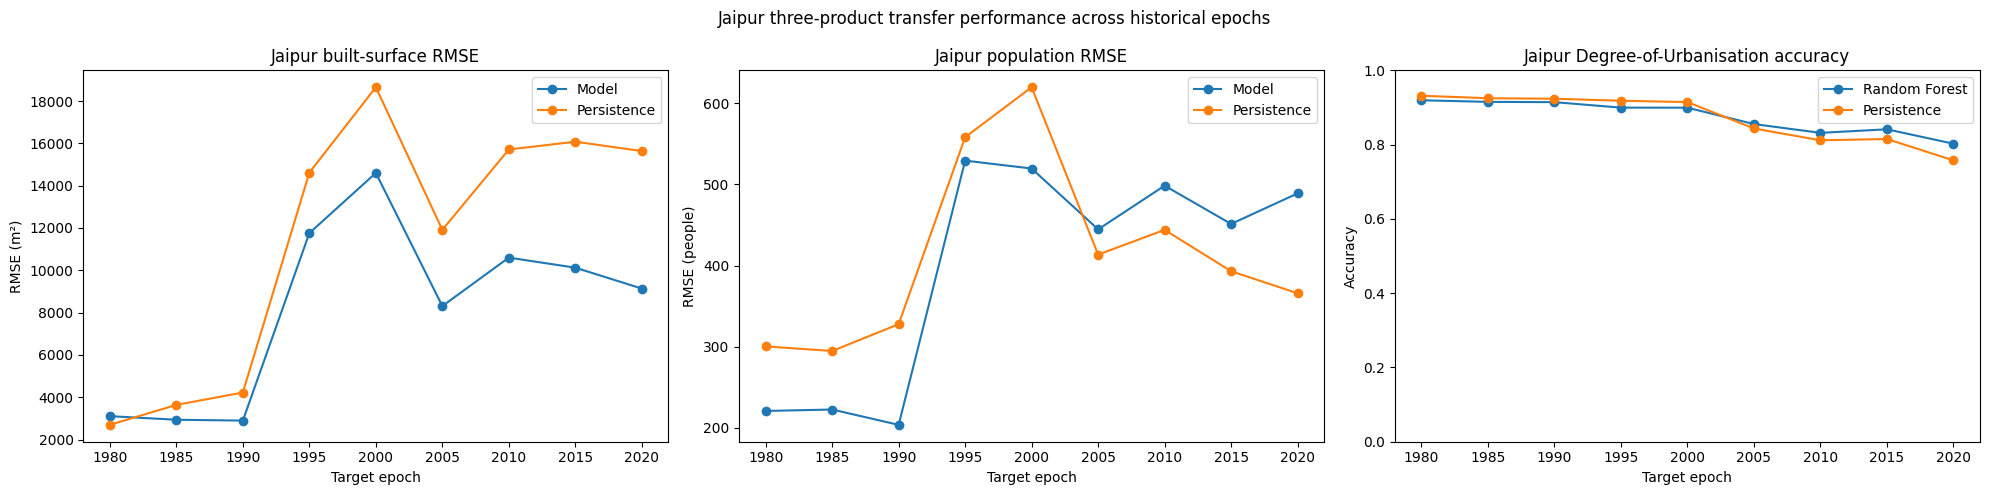

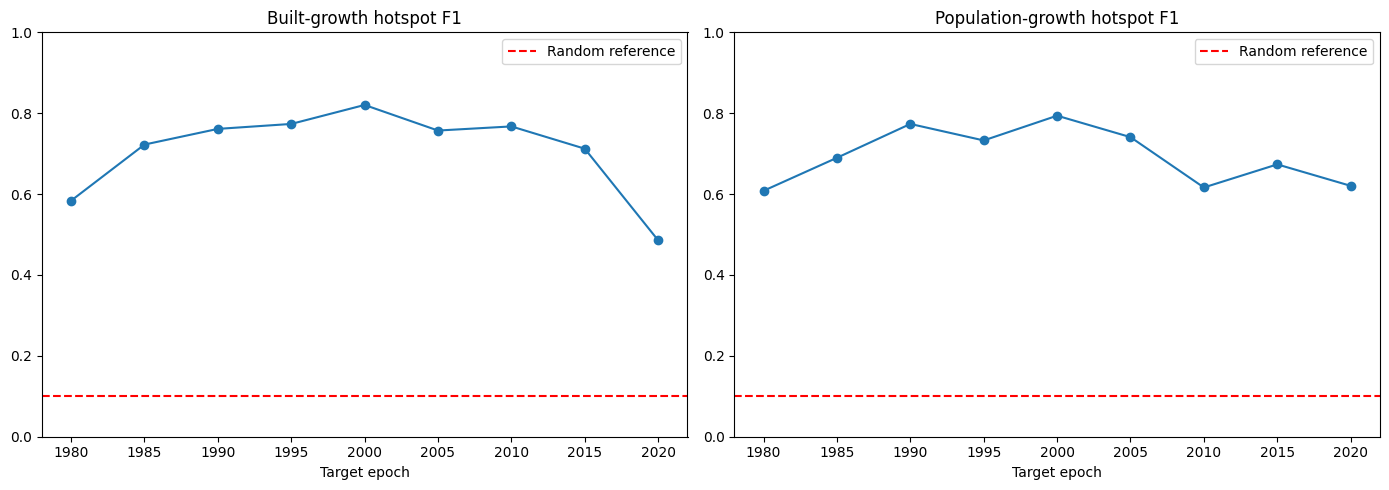

CELL 7: SUCCESS


In [7]:
# ============================================================
# CELL 7: ALL-EPOCH PERFORMANCE TREND FIGURES
# ============================================================
metric_data = pd.DataFrame([
    {
        'to_epoch': record['to_epoch'],
        'built_rmse': record['built_model']['rmse'],
        'built_persistence_rmse': record['built_persistence']['rmse'],
        'built_r2': record['built_model']['r2'],
        'built_hotspot_f1': record['built_hotspot_f1'],
        'population_rmse': record['population_model']['rmse'],
        'population_persistence_rmse': record['population_persistence']['rmse'],
        'population_r2': record['population_model']['r2'],
        'population_hotspot_f1': record['population_hotspot_f1'],
        'smod_accuracy': record['smod_accuracy'],
        'smod_persistence_accuracy': record['smod_persistence_accuracy'],
    }
    for record in RESULTS['metrics']
])

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_rmse, marker='o', label='Model')
axes[0].plot(metric_data.to_epoch, metric_data.built_persistence_rmse, marker='o', label='Persistence')
axes[0].set_title('Jaipur built-surface RMSE')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylabel('RMSE (m²)')
axes[0].legend()

axes[1].plot(metric_data.to_epoch, metric_data.population_rmse, marker='o', label='Model')
axes[1].plot(metric_data.to_epoch, metric_data.population_persistence_rmse, marker='o', label='Persistence')
axes[1].set_title('Jaipur population RMSE')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylabel('RMSE (people)')
axes[1].legend()

axes[2].plot(metric_data.to_epoch, metric_data.smod_accuracy, marker='o', label='Random Forest')
axes[2].plot(metric_data.to_epoch, metric_data.smod_persistence_accuracy, marker='o', label='Persistence')
axes[2].set_title('Jaipur Degree-of-Urbanisation accuracy')
axes[2].set_xlabel('Target epoch')
axes[2].set_ylabel('Accuracy')
axes[2].set_ylim(0, 1)
axes[2].legend()

fig.suptitle('Jaipur three-product transfer performance across historical epochs')
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'jaipur_three_product_performance_by_epoch.png', dpi=200)
plt.show()
plt.close()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(metric_data.to_epoch, metric_data.built_hotspot_f1, marker='o')
axes[0].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[0].set_title('Built-growth hotspot F1')
axes[0].set_xlabel('Target epoch')
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[1].plot(metric_data.to_epoch, metric_data.population_hotspot_f1, marker='o')
axes[1].axhline(0.10, color='red', linestyle='--', label='Random reference')
axes[1].set_title('Population-growth hotspot F1')
axes[1].set_xlabel('Target epoch')
axes[1].set_ylim(0, 1)
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURE_ROOT / 'jaipur_growth_hotspot_f1_by_epoch.png', dpi=200)
plt.show()
plt.close()

print('CELL 7: SUCCESS')

In [8]:
# ============================================================
# CELL 8: ACTUAL-VS-PREDICTED SCATTERS, RESIDUALS, CONFUSION
# Produces one figure set for each of the nine target epochs.
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'jaipur_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    specifications = [
        (
            'actual_next_built_surface_m2',
            'predicted_built_surface_m2',
            'Built surface',
            'm²',
        ),
        (
            'actual_next_population',
            'predicted_population',
            'Population',
            'people',
        ),
    ]
    for axis, (actual_column, predicted_column, title, unit) in zip(axes, specifications):
        actual = data[actual_column].astype(float)
        predicted = data[predicted_column].astype(float)
        minimum = min(actual.min(), predicted.min())
        maximum = max(actual.max(), predicted.max())
        axis.scatter(actual, predicted, s=7, alpha=0.28)
        axis.plot([minimum, maximum], [minimum, maximum], color='red', label='Perfect prediction')
        residual = predicted - actual
        rmse = np.sqrt(np.mean(residual ** 2))
        r2 = 1 - np.sum(residual ** 2) / np.sum((actual - actual.mean()) ** 2)
        axis.set_title(f'{title}: R²={r2:.4f}, RMSE={rmse:,.1f}')
        axis.set_xlabel(f'Actual {target_epoch} ({unit})')
        axis.set_ylabel(f'Predicted {target_epoch} ({unit})')
        axis.legend()
    fig.suptitle(f'Jaipur {source_epoch}→{target_epoch}: actual vs predicted')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'jaipur_{source_epoch}_{target_epoch}_actual_vs_predicted.png',
        dpi=200,
    )
    plt.close()

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].hist(data['built_error_m2'], bins=60)
    axes[0].axvline(0, color='red')
    axes[0].set_title('Built-surface errors')
    axes[0].set_xlabel('Predicted - actual (m²)')
    axes[1].hist(data['population_error'], bins=60)
    axes[1].axvline(0, color='red')
    axes[1].set_title('Population errors')
    axes[1].set_xlabel('Predicted - actual (people)')
    fig.suptitle(f'Jaipur {source_epoch}→{target_epoch}: error distributions')
    plt.tight_layout()
    plt.savefig(
        FIGURE_ROOT / f'jaipur_{source_epoch}_{target_epoch}_error_distributions.png',
        dpi=200,
    )
    plt.close()

    classes = sorted(
        set(data.actual_smod_class.astype(str))
        | set(data.predicted_smod_class.astype(str)),
        key=lambda value: int(float(value)),
    )
    confusion = pd.crosstab(
        data.actual_smod_class.astype(str),
        data.predicted_smod_class.astype(str),
    ).reindex(index=classes, columns=classes, fill_value=0)
    fig, axis = plt.subplots(figsize=(9, 7))
    image = axis.imshow(confusion.values, cmap='Blues')
    axis.set_xticks(range(len(classes)), classes, rotation=45)
    axis.set_yticks(range(len(classes)), classes)
    axis.set_xlabel('Predicted SMOD class')
    axis.set_ylabel('Actual SMOD class')
    axis.set_title(f'Jaipur SMOD confusion matrix, {target_epoch}')
    fig.colorbar(image, ax=axis)
    plt.tight_layout()
    plt.savefig(FIGURE_ROOT / f'jaipur_smod_confusion_{target_epoch}.png', dpi=200)
    plt.close()

print('Per-epoch scatter/residual/confusion figures created: 27')
print('CELL 8: SUCCESS')

Per-epoch scatter/residual/confusion figures created: 27
CELL 8: SUCCESS


In [9]:
# ============================================================
# CELL 9: SPATIAL THREE-PRODUCT MAPS FOR ALL NINE TARGET EPOCHS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'jaipur_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    if len(data) != 4900:
        raise RuntimeError(f'{target_epoch}: expected 4,900 rows.')

    def pivot(column):
        return data.pivot(
            index='grid_1km_row',
            columns='grid_1km_col',
            values=column,
        ).sort_index(ascending=False)

    specifications = [
        (
            'Built surface',
            pivot('actual_next_built_surface_m2'),
            pivot('predicted_built_surface_m2'),
            'YlOrRd',
        ),
        (
            'Population',
            pivot('actual_next_population'),
            pivot('predicted_population'),
            'viridis',
        ),
        (
            'Degree of Urbanisation',
            pivot('actual_smod_class'),
            pivot('predicted_smod_class'),
            'tab20',
        ),
    ]

    figure, axes = plt.subplots(3, 3, figsize=(18, 16))
    for row_index, (name, actual_map, predicted_map, color_map) in enumerate(specifications):
        actual_map = actual_map.astype(float)
        predicted_map = predicted_map.astype(float)
        error_map = predicted_map - actual_map

        if name == 'Degree of Urbanisation':
            minimum = min(np.nanmin(actual_map), np.nanmin(predicted_map))
            maximum = max(np.nanmax(actual_map), np.nanmax(predicted_map))
        else:
            pooled = np.concatenate([
                actual_map.values.ravel(),
                predicted_map.values.ravel(),
            ])
            minimum = np.nanpercentile(pooled, 1)
            maximum = np.nanpercentile(pooled, 99)

        image = axes[row_index, 0].imshow(
            actual_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 0].set_title(f'Actual {name}')
        figure.colorbar(image, ax=axes[row_index, 0], fraction=0.046)

        image = axes[row_index, 1].imshow(
            predicted_map, cmap=color_map, vmin=minimum, vmax=maximum
        )
        axes[row_index, 1].set_title(f'Predicted {name}')
        figure.colorbar(image, ax=axes[row_index, 1], fraction=0.046)

        error_limit = max(
            abs(np.nanpercentile(error_map.values, 1)),
            abs(np.nanpercentile(error_map.values, 99)),
            1,
        )
        image = axes[row_index, 2].imshow(
            error_map, cmap='coolwarm', vmin=-error_limit, vmax=error_limit
        )
        axes[row_index, 2].set_title(f'{name} error')
        figure.colorbar(image, ax=axes[row_index, 2], fraction=0.046)

        for axis in axes[row_index]:
            axis.set_axis_off()

    figure.suptitle(
        f'Jaipur {source_epoch}→{target_epoch}: actual vs predicted three-product comparison',
        fontsize=16,
    )
    plt.tight_layout()
    output_path = SPATIAL_ROOT / f'jaipur_{source_epoch}_{target_epoch}_three_product_spatial.png'
    plt.savefig(output_path, dpi=180, bbox_inches='tight')
    plt.close()

print('Three-product spatial figures created:', len(list(SPATIAL_ROOT.glob('*three_product_spatial.png'))))
print('CELL 9: SUCCESS')

Three-product spatial figures created: 9
CELL 9: SUCCESS


In [10]:
# ============================================================
# CELL 10: BUILT AND POPULATION GROWTH-HOTSPOT MAPS
# ============================================================
for target_epoch in TARGET_EPOCHS:
    source_epoch = target_epoch - 5
    data = pd.read_csv(
        ARTIFACT_ROOT / f'jaipur_{source_epoch}_{target_epoch}_three_product_predictions.csv'
    )
    hotspot_count = 490

    for prefix, actual_column, predicted_column, title in [
        (
            'built',
            'actual_built_growth_m2',
            'predicted_built_growth_m2',
            'Built-surface growth',
        ),
        (
            'population',
            'actual_population_change',
            'predicted_population_change',
            'Population growth',
        ),
    ]:
        actual_indices = set(
            data.nlargest(hotspot_count, actual_column).index
        )
        predicted_indices = set(
            data.nlargest(hotspot_count, predicted_column).index
        )
        correct_indices = actual_indices & predicted_indices

        data['actual_hotspot'] = data.index.isin(actual_indices)
        data['predicted_hotspot'] = data.index.isin(predicted_indices)
        data['correct_hotspot'] = data.index.isin(correct_indices)

        def pivot(column):
            return data.pivot(
                index='grid_1km_row',
                columns='grid_1km_col',
                values=column,
            ).sort_index(ascending=False)

        figure, axes = plt.subplots(1, 3, figsize=(16, 5))
        maps = [
            ('Actual top 10%', pivot('actual_hotspot'), 'Reds'),
            ('Predicted top 10%', pivot('predicted_hotspot'), 'Blues'),
            ('Correct overlap', pivot('correct_hotspot'), 'Greens'),
        ]
        for axis, (map_title, map_data, color_map) in zip(axes, maps):
            axis.imshow(map_data, cmap=color_map, vmin=0, vmax=1)
            axis.set_title(map_title)
            axis.set_axis_off()

        hotspot_f1 = len(correct_indices) / float(hotspot_count)
        figure.suptitle(
            f'Jaipur {source_epoch}→{target_epoch} {title} hotspots, F1={hotspot_f1:.2%}'
        )
        plt.tight_layout()
        plt.savefig(
            SPATIAL_ROOT / f'jaipur_{source_epoch}_{target_epoch}_{prefix}_hotspots.png',
            dpi=180,
            bbox_inches='tight',
        )
        plt.close()

print('Hotspot figures created:', len(list(SPATIAL_ROOT.glob('*hotspots.png'))))
print('CELL 10: SUCCESS')

Hotspot figures created: 18
CELL 10: SUCCESS


In [12]:
# ============================================================
# DISPLAY JAIPUR THREE-PRODUCT PREDICTIONS FOR EVERY EPOCH
#
# Add after Cell 5.
#
# Displays:
#   1975 -> 1980
#   1980 -> 1985
#   1985 -> 1990
#   1990 -> 1995
#   1995 -> 2000
#   2000 -> 2005
#   2005 -> 2010
#   2010 -> 2015
#   2015 -> 2020
#
# For each transition:
#   Row 1: Built surface actual, predicted, error
#   Row 2: Population actual, predicted, error
#   Row 3: SMOD actual, predicted, correctness
#
# Reads Google Drive CSV files only.
# Does not rerun Spark or modify HDFS.
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import (
    BoundaryNorm,
    ListedColormap,
)


# ============================================================
# REQUIRED VARIABLES AND PATHS
# ============================================================

if "ARTIFACT_ROOT" not in globals():
    ARTIFACT_ROOT = Path(
        "/content/drive/MyDrive/"
        "GHSL_Urban_Growth_Model/"
        "jaipur_three_product_evaluation_v1"
    )


if "FIGURE_ROOT" not in globals():
    FIGURE_ROOT = (
        ARTIFACT_ROOT
        / "figures"
    )


if "SPATIAL_ROOT" not in globals():
    SPATIAL_ROOT = (
        FIGURE_ROOT
        / "spatial"
    )


if "TARGET_EPOCHS" not in globals():
    TARGET_EPOCHS = [
        1980,
        1985,
        1990,
        1995,
        2000,
        2005,
        2010,
        2015,
        2020,
    ]


SPATIAL_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# SMOD CLASS LABELS
# ============================================================

SMOD_CLASS_LABELS = {
    0: "No data",
    10: "Water",
    11: "Very low-density rural",
    12: "Low-density rural",
    13: "Rural cluster",
    21: "Suburban / peri-urban",
    22: "Semi-dense urban cluster",
    23: "Dense urban cluster",
    30: "Urban centre",
}


SMOD_CLASS_ORDER = [
    0,
    10,
    11,
    12,
    13,
    21,
    22,
    23,
    30,
]


SMOD_COLORS = [
    "#d9d9d9",
    "#4f9bd9",
    "#eff3c6",
    "#c8e6a0",
    "#78c679",
    "#fdae61",
    "#f46d43",
    "#d73027",
    "#7f0000",
]


smod_color_map = ListedColormap(
    SMOD_COLORS
)


smod_boundaries = [
    -0.5,
    5,
    10.5,
    11.5,
    12.5,
    17,
    21.5,
    22.5,
    26.5,
    30.5,
]


smod_normalization = BoundaryNorm(
    smod_boundaries,
    smod_color_map.N,
)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def make_grid(
    dataframe,
    value_column,
):
    return (
        dataframe
        .pivot(
            index="grid_1km_row",
            columns="grid_1km_col",
            values=value_column,
        )
        .sort_index(
            ascending=False
        )
    )


def percentile_range(
    actual_grid,
    predicted_grid,
    lower_percentile=1,
    upper_percentile=99,
):
    combined_values = np.concatenate(
        [
            actual_grid
            .to_numpy()
            .ravel(),
            predicted_grid
            .to_numpy()
            .ravel(),
        ]
    )

    finite_values = combined_values[
        np.isfinite(
            combined_values
        )
    ]

    if len(finite_values) == 0:
        return (
            0.0,
            1.0,
        )

    lower_value = np.nanpercentile(
        finite_values,
        lower_percentile,
    )

    upper_value = np.nanpercentile(
        finite_values,
        upper_percentile,
    )

    if lower_value == upper_value:
        upper_value = (
            lower_value
            + 1.0
        )

    return (
        lower_value,
        upper_value,
    )


def symmetric_error_limit(
    error_grid,
):
    finite_errors = (
        error_grid
        .to_numpy()
        .ravel()
    )

    finite_errors = finite_errors[
        np.isfinite(
            finite_errors
        )
    ]

    if len(finite_errors) == 0:
        return 1.0

    limit = max(
        abs(
            np.nanpercentile(
                finite_errors,
                1,
            )
        ),
        abs(
            np.nanpercentile(
                finite_errors,
                99,
            )
        ),
        1.0,
    )

    return limit


# ============================================================
# LOAD, VALIDATE, DISPLAY, AND SAVE EACH TRANSITION
# ============================================================

displayed_figures = []


for target_epoch in TARGET_EPOCHS:
    source_epoch = (
        target_epoch
        - 5
    )

    prediction_path = (
        ARTIFACT_ROOT
        / (
            "jaipur_"
            + str(source_epoch)
            + "_"
            + str(target_epoch)
            + "_three_product_predictions.csv"
        )
    )


    if not prediction_path.is_file():
        raise FileNotFoundError(
            "The required Jaipur prediction CSV is missing: "
            + str(
                prediction_path
            )
            + ". Run Cell 5 first."
        )


    predictions = pd.read_csv(
        prediction_path
    )


    if len(predictions) != 4900:
        raise RuntimeError(
            str(
                source_epoch
            )
            + "->"
            + str(
                target_epoch
            )
            + ": expected 4,900 rows, found "
            + str(
                len(
                    predictions
                )
            )
        )


    required_columns = {
        "grid_1km_row",
        "grid_1km_col",
        "actual_next_built_surface_m2",
        "predicted_built_surface_m2",
        "actual_next_population",
        "predicted_population",
        "actual_smod_class",
        "predicted_smod_class",
    }


    missing_columns = sorted(
        required_columns
        - set(
            predictions.columns
        )
    )


    if missing_columns:
        raise RuntimeError(
            str(
                prediction_path
            )
            + " is missing columns: "
            + repr(
                missing_columns
            )
        )


    # ========================================================
    # BUILD THE SIX ACTUAL/PREDICTED GRIDS
    # ========================================================

    actual_built = make_grid(
        predictions,
        "actual_next_built_surface_m2",
    )

    predicted_built = make_grid(
        predictions,
        "predicted_built_surface_m2",
    )

    built_error = (
        predicted_built
        - actual_built
    )


    actual_population = make_grid(
        predictions,
        "actual_next_population",
    )

    predicted_population = make_grid(
        predictions,
        "predicted_population",
    )

    population_error = (
        predicted_population
        - actual_population
    )


    actual_smod = make_grid(
        predictions,
        "actual_smod_class",
    ).astype(
        float
    )

    predicted_smod = make_grid(
        predictions,
        "predicted_smod_class",
    ).astype(
        float
    )


    smod_correct = (
        predicted_smod
        == actual_smod
    ).astype(
        int
    )


    # ========================================================
    # CONSISTENT ACTUAL/PREDICTED COLOR RANGES
    # ========================================================

    (
        built_minimum,
        built_maximum,
    ) = percentile_range(
        actual_built,
        predicted_built,
    )


    built_error_limit = symmetric_error_limit(
        built_error
    )


    (
        population_minimum,
        population_maximum,
    ) = percentile_range(
        actual_population,
        predicted_population,
    )


    population_error_limit = symmetric_error_limit(
        population_error
    )


    # ========================================================
    # CREATE 3 x 3 FIGURE
    # ========================================================

    figure, axes = plt.subplots(
        3,
        3,
        figsize=(
            19,
            17,
        ),
    )


    # --------------------------------------------------------
    # ROW 1: BUILT SURFACE
    # --------------------------------------------------------

    image = axes[
        0,
        0,
    ].imshow(
        actual_built,
        cmap="YlOrRd",
        vmin=built_minimum,
        vmax=built_maximum,
    )

    axes[
        0,
        0,
    ].set_title(
        "Actual built surface "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            0,
        ],
        fraction=0.046,
        label="Built surface (m²)",
    )


    image = axes[
        0,
        1,
    ].imshow(
        predicted_built,
        cmap="YlOrRd",
        vmin=built_minimum,
        vmax=built_maximum,
    )

    axes[
        0,
        1,
    ].set_title(
        "Predicted built surface "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            1,
        ],
        fraction=0.046,
        label="Built surface (m²)",
    )


    image = axes[
        0,
        2,
    ].imshow(
        built_error,
        cmap="coolwarm",
        vmin=-built_error_limit,
        vmax=built_error_limit,
    )

    axes[
        0,
        2,
    ].set_title(
        "Built-surface error\n"
        "predicted - actual"
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            2,
        ],
        fraction=0.046,
        label="Error (m²)",
    )


    # --------------------------------------------------------
    # ROW 2: POPULATION
    # --------------------------------------------------------

    image = axes[
        1,
        0,
    ].imshow(
        actual_population,
        cmap="viridis",
        vmin=population_minimum,
        vmax=population_maximum,
    )

    axes[
        1,
        0,
    ].set_title(
        "Actual population "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            0,
        ],
        fraction=0.046,
        label="Estimated residents",
    )


    image = axes[
        1,
        1,
    ].imshow(
        predicted_population,
        cmap="viridis",
        vmin=population_minimum,
        vmax=population_maximum,
    )

    axes[
        1,
        1,
    ].set_title(
        "Predicted population "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            1,
        ],
        fraction=0.046,
        label="Estimated residents",
    )


    image = axes[
        1,
        2,
    ].imshow(
        population_error,
        cmap="coolwarm",
        vmin=-population_error_limit,
        vmax=population_error_limit,
    )

    axes[
        1,
        2,
    ].set_title(
        "Population error\n"
        "predicted - actual"
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            2,
        ],
        fraction=0.046,
        label="Error (people)",
    )


    # --------------------------------------------------------
    # ROW 3: DEGREE OF URBANISATION
    # --------------------------------------------------------

    image = axes[
        2,
        0,
    ].imshow(
        actual_smod,
        cmap=smod_color_map,
        norm=smod_normalization,
    )

    axes[
        2,
        0,
    ].set_title(
        "Actual Degree of Urbanisation "
        + str(
            target_epoch
        )
    )


    image = axes[
        2,
        1,
    ].imshow(
        predicted_smod,
        cmap=smod_color_map,
        norm=smod_normalization,
    )

    axes[
        2,
        1,
    ].set_title(
        "Predicted Degree of Urbanisation "
        + str(
            target_epoch
        )
    )


    image = axes[
        2,
        2,
    ].imshow(
        smod_correct,
        cmap=ListedColormap(
            [
                "#d73027",
                "#1a9850",
            ]
        ),
        vmin=0,
        vmax=1,
    )

    axes[
        2,
        2,
    ].set_title(
        "SMOD classification agreement\n"
        "red = incorrect, green = correct"
    )


    # --------------------------------------------------------
    # CLEAN MAP FORMATTING
    # --------------------------------------------------------

    for axis_row in axes:
        for axis in axis_row:
            axis.set_axis_off()


    # Add common SMOD legend underneath the figure.
    legend_handles = [
        plt.Line2D(
            [
                0
            ],
            [
                0
            ],
            marker="s",
            linestyle="",
            markersize=9,
            markerfacecolor=SMOD_COLORS[
                index
            ],
            markeredgecolor="none",
            label=(
                str(
                    smod_class
                )
                + ": "
                + SMOD_CLASS_LABELS[
                    smod_class
                ]
            ),
        )
        for (
            index,
            smod_class,
        ) in enumerate(
            SMOD_CLASS_ORDER
        )
    ]


    figure.legend(
        handles=legend_handles,
        loc="lower center",
        ncol=3,
        fontsize=9,
        bbox_to_anchor=(
            0.5,
            0.01,
        ),
    )


    figure.suptitle(
        (
            "Jaipur "
            + str(
                source_epoch
            )
            + "→"
            + str(
                target_epoch
            )
            + ": actual versus predicted GHSL products"
        ),
        fontsize=18,
        y=0.995,
    )


    plt.tight_layout(
        rect=[
            0,
            0.07,
            1,
            0.97,
        ]
    )


    output_path = (
        SPATIAL_ROOT
        / (
            "jaipur_"
            + str(
                source_epoch
            )
            + "_"
            + str(
                target_epoch
            )
            + "_three_product_spatial_display.png"
        )
    )


    plt.savefig(
        output_path,
        dpi=180,
        bbox_inches="tight",
    )


    # This line makes the figure visible in Colab.
    plt.show()


    plt.close(
        figure
    )


    displayed_figures.append(
        str(
            output_path
        )
    )


    smod_accuracy = (
        smod_correct
        .to_numpy()
        .mean()
    )


    print(
        "Displayed:",
        str(
            source_epoch
        )
        + "->"
        + str(
            target_epoch
        ),
        "| SMOD accuracy:",
        f"{smod_accuracy:.2%}",
        "| Saved:",
        output_path.name,
    )


# ============================================================
# FINAL CHECK
# ============================================================

if len(
    displayed_figures
) != 9:
    raise RuntimeError(
        "Expected nine displayed spatial figures, created "
        + str(
            len(
                displayed_figures
            )
        )
    )


print()
print(
    "Jaipur transition figures displayed:",
    len(
        displayed_figures
    ),
)

print(
    "Figure directory:",
    SPATIAL_ROOT,
)

print(
    "DISPLAY JAIPUR ALL-EPOCH SPATIAL PREDICTIONS: SUCCESS"
)

Output hidden; open in https://colab.research.google.com to view.

In [11]:
# ============================================================
# CELL 11: SAVE FINAL MANIFEST AND COMPLETION GATE
# ============================================================
primary_result = next(
    record for record in RESULTS['metrics'] if record['to_epoch'] == 2020
)

manifest = {
    'created_at_utc': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
    'city': 'Jaipur Metropolitan Region',
    'city_slug': 'jaipur',
    'jaipur_used_in_training': False,
    'actual_epochs': ACTUAL_EPOCHS,
    'prediction_target_epochs': TARGET_EPOCHS,
    'baseline_epoch_without_prediction': 1975,
    'prediction_comparisons': 9,
    'rows_per_comparison': 4900,
    'total_prediction_rows': 44100,
    'models': {
        'built_surface': {
            'type': 'Linear Regression',
            'path': BUILT_MODEL,
            'target': 'built_surface_total_m2',
        },
        'population': {
            'type': 'Linear Regression',
            'path': POPULATION_MODEL,
            'target': 'population_total',
        },
        'degree_of_urbanisation': {
            'type': 'Random Forest Classifier',
            'path': SMOD_MODEL,
            'target': 'smod_class',
        },
    },
    'primary_unseen_city_unseen_time_test': '2015->2020',
    'primary_2015_2020_metrics': primary_result,
    'hdfs_outputs': {
        'transitions': JAIPUR_THREE_TARGET_TRANSITIONS,
        'cell_predictions': CELL_PREDICTIONS,
        'summary_tables': SUMMARY_TABLES,
    },
    'drive_output': str(ARTIFACT_ROOT),
    'figures': len(list(FIGURE_ROOT.rglob('*.png'))),
    'source_datasets_modified': False,
}

manifest_path = ARTIFACT_ROOT / 'jaipur_three_product_evaluation_manifest.json'
manifest_path.write_text(
    json.dumps(manifest, indent=2, sort_keys=True) + '\n',
    encoding='utf-8',
)

print('Jaipur actual epochs available: 10/10')
print('Five-year prediction comparisons: 9/9')
print('1975 retained as observed baseline: YES')
print('Built-surface predictions evaluated: COMPLETE')
print('Population predictions evaluated: COMPLETE')
print('Degree-of-Urbanisation predictions evaluated: COMPLETE')
print('Persistence comparisons: COMPLETE')
print('All-epoch metrics and CSV exports: COMPLETE')
print('All-epoch actual-vs-predicted figures: COMPLETE')
print('All-epoch spatial figures: COMPLETE')
print('All-epoch growth-hotspot figures: COMPLETE')
print('Primary 2015->2020 transfer test: COMPLETE')
print('Jaipur used in training: NO')
print('Source HDFS datasets modified: NO')
print('NOTEBOOK_18_JAIPUR_THREE_PRODUCT_EVALUATION_SUCCESS')
print('CELL 11: SUCCESS')

Jaipur actual epochs available: 10/10
Five-year prediction comparisons: 9/9
1975 retained as observed baseline: YES
Built-surface predictions evaluated: COMPLETE
Population predictions evaluated: COMPLETE
Degree-of-Urbanisation predictions evaluated: COMPLETE
Persistence comparisons: COMPLETE
All-epoch metrics and CSV exports: COMPLETE
All-epoch actual-vs-predicted figures: COMPLETE
All-epoch spatial figures: COMPLETE
All-epoch growth-hotspot figures: COMPLETE
Primary 2015->2020 transfer test: COMPLETE
Jaipur used in training: NO
Source HDFS datasets modified: NO
NOTEBOOK_18_JAIPUR_THREE_PRODUCT_EVALUATION_SUCCESS
CELL 11: SUCCESS


In [13]:
# ============================================================
# CELL 12:
# CONSISTENT JAIPUR THREE-PRODUCT SPATIAL EVALUATION
#
# Run after Cell 11.
#
# For every Jaipur transition:
#   Row 1:
#       Actual built surface
#       Predicted built surface
#       Signed built-surface error
#
#   Row 2:
#       Actual population
#       Predicted population
#       Signed population error
#
#   Row 3:
#       Actual Degree of Urbanisation
#       Predicted Degree of Urbanisation
#       Correct/incorrect classification
#
# Also displays:
#   - Built-surface MAE, RMSE, R² and bias
#   - Population MAE, RMSE, R² and bias
#   - SMOD model and persistence accuracy
#
# Reads the nine existing Drive CSV files only.
# Does not run Spark or modify HDFS.
# ============================================================

from pathlib import Path

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.colors import (
    BoundaryNorm,
    ListedColormap,
)

from matplotlib.patches import (
    Patch,
)


# ============================================================
# PATHS
# ============================================================

RESULT_ROOT = Path(
    "/content/drive/MyDrive/"
    "GHSL_Urban_Growth_Model/"
    "jaipur_three_product_evaluation_v1"
)

FIGURE_ROOT = (
    RESULT_ROOT
    / "figures"
    / "consistent_spatial"
)

FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


TARGET_EPOCHS = [
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


# ============================================================
# SMOD CLASS CONFIGURATION
#
# These are categorical values, not continuous quantities.
# The same class colors are used in every epoch.
# ============================================================

SMOD_CLASS_LABELS = {
    0: "No data",
    10: "Water",
    11: "Very low-density rural",
    12: "Low-density rural",
    13: "Rural cluster",
    21: "Suburban / peri-urban",
    22: "Semi-dense urban cluster",
    23: "Dense urban cluster",
    30: "Urban centre",
}


SMOD_CLASS_ORDER = [
    0,
    10,
    11,
    12,
    13,
    21,
    22,
    23,
    30,
]


SMOD_COLORS = [
    "#d9d9d9",  # 0
    "#4f9bd9",  # 10
    "#ffffcc",  # 11
    "#c7e9b4",  # 12
    "#41ab5d",  # 13
    "#fdae61",  # 21
    "#f46d43",  # 22
    "#d73027",  # 23
    "#7f0000",  # 30
]


SMOD_CMAP = ListedColormap(
    SMOD_COLORS
)


# Convert original SMOD codes to compact positions 0-8.
# This ensures a truly categorical color scale.

SMOD_TO_POSITION = {
    smod_class: position
    for position, smod_class
    in enumerate(
        SMOD_CLASS_ORDER
    )
}


SMOD_NORM = BoundaryNorm(
    np.arange(
        -0.5,
        len(
            SMOD_CLASS_ORDER
        )
        + 0.5,
        1.0,
    ),
    SMOD_CMAP.N,
)


AGREEMENT_CMAP = ListedColormap(
    [
        "#d73027",  # incorrect
        "#1a9850",  # correct
    ]
)


# ============================================================
# HELPERS
# ============================================================

def make_grid(
    dataframe,
    column_name,
):
    grid = (
        dataframe
        .pivot(
            index="grid_1km_row",
            columns="grid_1km_col",
            values=column_name,
        )
        .sort_index(
            ascending=False
        )
    )

    if grid.shape != (
        70,
        70,
    ):
        raise RuntimeError(
            column_name
            + ": expected a 70 x 70 grid, found "
            + repr(
                grid.shape
            )
        )

    return grid


def regression_metrics(
    observed,
    predicted,
):
    observed = np.asarray(
        observed,
        dtype=float,
    )

    predicted = np.asarray(
        predicted,
        dtype=float,
    )

    residual = (
        predicted
        - observed
    )

    valid = (
        np.isfinite(
            observed
        )
        & np.isfinite(
            predicted
        )
    )

    observed = observed[
        valid
    ]

    predicted = predicted[
        valid
    ]

    residual = residual[
        valid
    ]

    mae = np.mean(
        np.abs(
            residual
        )
    )

    rmse = np.sqrt(
        np.mean(
            residual ** 2
        )
    )

    denominator = np.sum(
        (
            observed
            - observed.mean()
        )
        ** 2
    )

    r2 = (
        np.nan
        if denominator == 0
        else (
            1.0
            - (
                np.sum(
                    residual ** 2
                )
                / denominator
            )
        )
    )

    bias = np.mean(
        residual
    )

    return {
        "mae": float(
            mae
        ),
        "rmse": float(
            rmse
        ),
        "r2": float(
            r2
        ),
        "bias": float(
            bias
        ),
    }


def actual_prediction_range(
    actual_grid,
    predicted_grid,
):
    pooled = np.concatenate(
        [
            actual_grid
            .to_numpy()
            .ravel(),
            predicted_grid
            .to_numpy()
            .ravel(),
        ]
    )

    pooled = pooled[
        np.isfinite(
            pooled
        )
    ]

    if len(
        pooled
    ) == 0:
        return (
            0.0,
            1.0,
        )

    # Keep zero as the lower bound because both built surface
    # and population are non-negative.

    minimum = 0.0

    maximum = np.nanpercentile(
        pooled,
        99.5,
    )

    if maximum <= minimum:
        maximum = (
            minimum
            + 1.0
        )

    return (
        minimum,
        maximum,
    )


def symmetric_error_range(
    error_grid,
):
    values = (
        error_grid
        .to_numpy()
        .ravel()
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    if len(
        values
    ) == 0:
        return 1.0

    limit = np.nanpercentile(
        np.abs(
            values
        ),
        99.0,
    )

    return max(
        float(
            limit
        ),
        1.0,
    )


def categorical_smod_grid(
    raw_grid,
):
    mapped = raw_grid.replace(
        SMOD_TO_POSITION
    )

    unknown_values = sorted(
        set(
            np.unique(
                raw_grid
                .dropna()
                .to_numpy()
            )
        )
        - set(
            SMOD_CLASS_ORDER
        )
    )

    if unknown_values:
        raise RuntimeError(
            "Unknown SMOD classes found: "
            + repr(
                unknown_values
            )
        )

    return mapped.astype(
        float
    )


# ============================================================
# FIGURE INVENTORY
# ============================================================

figure_inventory = []


# ============================================================
# PROCESS ALL NINE FIVE-YEAR TRANSITIONS
# ============================================================

for target_epoch in TARGET_EPOCHS:
    source_epoch = (
        target_epoch
        - 5
    )

    prediction_path = (
        RESULT_ROOT
        / (
            "jaipur_"
            + str(
                source_epoch
            )
            + "_"
            + str(
                target_epoch
            )
            + "_three_product_predictions.csv"
        )
    )


    if not prediction_path.is_file():
        raise FileNotFoundError(
            "Missing prediction file: "
            + str(
                prediction_path
            )
        )


    predictions = pd.read_csv(
        prediction_path
    )


    if len(
        predictions
    ) != 4900:
        raise RuntimeError(
            str(
                source_epoch
            )
            + "->"
            + str(
                target_epoch
            )
            + ": expected 4,900 cells, found "
            + str(
                len(
                    predictions
                )
            )
        )


    required_columns = {
        "grid_cell_id",
        "grid_1km_row",
        "grid_1km_col",
        "built_surface_total_m2",
        "actual_next_built_surface_m2",
        "predicted_built_surface_m2",
        "population_total",
        "actual_next_population",
        "predicted_population",
        "smod_class",
        "actual_smod_class",
        "predicted_smod_class",
    }


    missing_columns = sorted(
        required_columns
        - set(
            predictions.columns
        )
    )


    if missing_columns:
        raise RuntimeError(
            prediction_path.name
            + " is missing columns: "
            + repr(
                missing_columns
            )
        )


    # ========================================================
    # METRICS
    # ========================================================

    built_metrics = regression_metrics(
        predictions[
            "actual_next_built_surface_m2"
        ],
        predictions[
            "predicted_built_surface_m2"
        ],
    )


    population_metrics = regression_metrics(
        predictions[
            "actual_next_population"
        ],
        predictions[
            "predicted_population"
        ],
    )


    actual_smod_values = (
        predictions[
            "actual_smod_class"
        ]
        .astype(
            int
        )
    )


    predicted_smod_values = (
        predictions[
            "predicted_smod_class"
        ]
        .astype(
            int
        )
    )


    current_smod_values = (
        predictions[
            "smod_class"
        ]
        .astype(
            int
        )
    )


    smod_accuracy = np.mean(
        predicted_smod_values
        == actual_smod_values
    )


    smod_persistence_accuracy = np.mean(
        current_smod_values
        == actual_smod_values
    )


    # ========================================================
    # GRIDS
    # ========================================================

    actual_built = make_grid(
        predictions,
        "actual_next_built_surface_m2",
    )

    predicted_built = make_grid(
        predictions,
        "predicted_built_surface_m2",
    )

    built_error = (
        predicted_built
        - actual_built
    )


    actual_population = make_grid(
        predictions,
        "actual_next_population",
    )

    predicted_population = make_grid(
        predictions,
        "predicted_population",
    )

    population_error = (
        predicted_population
        - actual_population
    )


    actual_smod_raw = make_grid(
        predictions,
        "actual_smod_class",
    )

    predicted_smod_raw = make_grid(
        predictions,
        "predicted_smod_class",
    )


    actual_smod = categorical_smod_grid(
        actual_smod_raw
    )

    predicted_smod = categorical_smod_grid(
        predicted_smod_raw
    )


    smod_agreement = (
        actual_smod_raw
        == predicted_smod_raw
    ).astype(
        int
    )


    # ========================================================
    # COMMON SCALES FOR ACTUAL AND PREDICTED PANELS
    # ========================================================

    (
        built_minimum,
        built_maximum,
    ) = actual_prediction_range(
        actual_built,
        predicted_built,
    )


    built_error_limit = symmetric_error_range(
        built_error
    )


    (
        population_minimum,
        population_maximum,
    ) = actual_prediction_range(
        actual_population,
        predicted_population,
    )


    population_error_limit = symmetric_error_range(
        population_error
    )


    # ========================================================
    # FIGURE
    # ========================================================

    figure, axes = plt.subplots(
        3,
        3,
        figsize=(
            20,
            17,
        ),
    )


    # --------------------------------------------------------
    # BUILT-SURFACE ROW
    # --------------------------------------------------------

    image = axes[
        0,
        0,
    ].imshow(
        actual_built,
        cmap="YlOrRd",
        vmin=built_minimum,
        vmax=built_maximum,
    )

    axes[
        0,
        0,
    ].set_title(
        "Actual built surface "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            0,
        ],
        fraction=0.046,
        label="Built surface (m²)",
    )


    image = axes[
        0,
        1,
    ].imshow(
        predicted_built,
        cmap="YlOrRd",
        vmin=built_minimum,
        vmax=built_maximum,
    )

    axes[
        0,
        1,
    ].set_title(
        "Predicted built surface "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            1,
        ],
        fraction=0.046,
        label="Built surface (m²)",
    )


    image = axes[
        0,
        2,
    ].imshow(
        built_error,
        cmap="coolwarm",
        vmin=-built_error_limit,
        vmax=built_error_limit,
    )

    axes[
        0,
        2,
    ].set_title(
        "Built-surface error\n"
        "predicted - actual"
    )

    figure.colorbar(
        image,
        ax=axes[
            0,
            2,
        ],
        fraction=0.046,
        label="Error (m²)",
    )


    axes[
        0,
        1,
    ].text(
        0.5,
        -0.08,
        (
            "MAE="
            + f'{built_metrics["mae"]:,.1f}'
            + " m² | RMSE="
            + f'{built_metrics["rmse"]:,.1f}'
            + " m² | R²="
            + f'{built_metrics["r2"]:.4f}'
            + " | Bias="
            + f'{built_metrics["bias"]:+,.1f}'
            + " m²"
        ),
        transform=axes[
            0,
            1,
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.3",
            "facecolor": "white",
            "alpha": 0.85,
            "edgecolor": "#aaaaaa",
        },
    )


    # --------------------------------------------------------
    # POPULATION ROW
    # --------------------------------------------------------

    image = axes[
        1,
        0,
    ].imshow(
        actual_population,
        cmap="viridis",
        vmin=population_minimum,
        vmax=population_maximum,
    )

    axes[
        1,
        0,
    ].set_title(
        "Actual population "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            0,
        ],
        fraction=0.046,
        label="Estimated residents",
    )


    image = axes[
        1,
        1,
    ].imshow(
        predicted_population,
        cmap="viridis",
        vmin=population_minimum,
        vmax=population_maximum,
    )

    axes[
        1,
        1,
    ].set_title(
        "Predicted population "
        + str(
            target_epoch
        )
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            1,
        ],
        fraction=0.046,
        label="Estimated residents",
    )


    image = axes[
        1,
        2,
    ].imshow(
        population_error,
        cmap="coolwarm",
        vmin=-population_error_limit,
        vmax=population_error_limit,
    )

    axes[
        1,
        2,
    ].set_title(
        "Population error\n"
        "predicted - actual"
    )

    figure.colorbar(
        image,
        ax=axes[
            1,
            2,
        ],
        fraction=0.046,
        label="Error (people)",
    )


    axes[
        1,
        1,
    ].text(
        0.5,
        -0.08,
        (
            "MAE="
            + f'{population_metrics["mae"]:,.1f}'
            + " people | RMSE="
            + f'{population_metrics["rmse"]:,.1f}'
            + " | R²="
            + f'{population_metrics["r2"]:.4f}'
            + " | Bias="
            + f'{population_metrics["bias"]:+,.1f}'
        ),
        transform=axes[
            1,
            1,
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.3",
            "facecolor": "white",
            "alpha": 0.85,
            "edgecolor": "#aaaaaa",
        },
    )


    # --------------------------------------------------------
    # DEGREE-OF-URBANISATION ROW
    # --------------------------------------------------------

    axes[
        2,
        0,
    ].imshow(
        actual_smod,
        cmap=SMOD_CMAP,
        norm=SMOD_NORM,
    )

    axes[
        2,
        0,
    ].set_title(
        "Actual Degree of Urbanisation "
        + str(
            target_epoch
        )
    )


    axes[
        2,
        1,
    ].imshow(
        predicted_smod,
        cmap=SMOD_CMAP,
        norm=SMOD_NORM,
    )

    axes[
        2,
        1,
    ].set_title(
        "Predicted Degree of Urbanisation "
        + str(
            target_epoch
        )
    )


    axes[
        2,
        2,
    ].imshow(
        smod_agreement,
        cmap=AGREEMENT_CMAP,
        vmin=0,
        vmax=1,
    )

    axes[
        2,
        2,
    ].set_title(
        "SMOD classification agreement\n"
        "red = incorrect, green = correct"
    )


    axes[
        2,
        1,
    ].text(
        0.5,
        -0.08,
        (
            "Random Forest accuracy="
            + f"{smod_accuracy:.2%}"
            + " | Persistence accuracy="
            + f"{smod_persistence_accuracy:.2%}"
            + " | Difference="
            + f"{(smod_accuracy - smod_persistence_accuracy):+.2%}"
        ),
        transform=axes[
            2,
            1,
        ].transAxes,
        ha="center",
        va="top",
        fontsize=10,
        bbox={
            "boxstyle": "round,pad=0.3",
            "facecolor": "white",
            "alpha": 0.85,
            "edgecolor": "#aaaaaa",
        },
    )


    # --------------------------------------------------------
    # MAP FORMATTING
    # --------------------------------------------------------

    for axis_row in axes:
        for axis in axis_row:
            axis.set_axis_off()


    # --------------------------------------------------------
    # CATEGORICAL LEGENDS
    # --------------------------------------------------------

    smod_legend_handles = [
        Patch(
            facecolor=SMOD_COLORS[
                index
            ],
            edgecolor="none",
            label=(
                str(
                    smod_class
                )
                + ": "
                + SMOD_CLASS_LABELS[
                    smod_class
                ]
            ),
        )
        for (
            index,
            smod_class,
        ) in enumerate(
            SMOD_CLASS_ORDER
        )
    ]


    agreement_legend_handles = [
        Patch(
            facecolor="#1a9850",
            label="Correct class",
        ),
        Patch(
            facecolor="#d73027",
            label="Incorrect class",
        ),
    ]


    figure.legend(
        handles=smod_legend_handles,
        loc="lower center",
        ncol=3,
        fontsize=9,
        bbox_to_anchor=(
            0.42,
            0.004,
        ),
        title="Degree-of-Urbanisation classes",
    )


    figure.legend(
        handles=agreement_legend_handles,
        loc="lower center",
        ncol=2,
        fontsize=9,
        bbox_to_anchor=(
            0.81,
            0.025,
        ),
        title="Classification result",
    )


    figure.suptitle(
        (
            "Jaipur "
            + str(
                source_epoch
            )
            + "→"
            + str(
                target_epoch
            )
            + ": actual versus predicted GHSL products"
        ),
        fontsize=18,
        y=0.995,
    )


    plt.tight_layout(
        rect=[
            0,
            0.105,
            1,
            0.97,
        ]
    )


    output_path = (
        FIGURE_ROOT
        / (
            "jaipur_"
            + str(
                source_epoch
            )
            + "_"
            + str(
                target_epoch
            )
            + "_consistent_three_product_comparison.png"
        )
    )


    plt.savefig(
        output_path,
        dpi=200,
        bbox_inches="tight",
    )


    plt.show()


    plt.close(
        figure
    )


    figure_inventory.append(
        {
            "from_epoch": (
                source_epoch
            ),
            "to_epoch": (
                target_epoch
            ),
            "path": str(
                output_path
            ),
            "built_metrics": (
                built_metrics
            ),
            "population_metrics": (
                population_metrics
            ),
            "smod_accuracy": float(
                smod_accuracy
            ),
            "smod_persistence_accuracy": float(
                smod_persistence_accuracy
            ),
        }
    )


    print(
        "Completed:",
        str(
            source_epoch
        )
        + "->"
        + str(
            target_epoch
        ),
        "| Built RMSE:",
        f'{built_metrics["rmse"]:,.1f} m²',
        "| Population RMSE:",
        f'{population_metrics["rmse"]:,.1f}',
        "| SMOD accuracy:",
        f"{smod_accuracy:.2%}",
    )


# ============================================================
# SAVE FIGURE INVENTORY
# ============================================================

if len(
    figure_inventory
) != 9:
    raise RuntimeError(
        "Expected nine figures, created "
        + str(
            len(
                figure_inventory
            )
        )
    )


inventory_path = (
    RESULT_ROOT
    / "consistent_spatial_figure_inventory.json"
)


inventory_path.write_text(
    json.dumps(
        figure_inventory,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


print()
print(
    "Consistent Jaipur spatial figures:",
    len(
        figure_inventory
    ),
)

print(
    "Saved under:",
    FIGURE_ROOT,
)

print(
    "Inventory:",
    inventory_path,
)

print(
    "CONSISTENT JAIPUR THREE-PRODUCT FIGURES: SUCCESS"
)

Output hidden; open in https://colab.research.google.com to view.

In [14]:
# ============================================================
# EXPORT AUTHORITATIVE JAIPUR METRIC TABLE FROM HDFS
#
# Reads:
#   HDFS Parquet summary produced by Notebook 18
#
# Creates:
#   - Complete all-epoch metrics CSV
#   - Compact report table CSV
#   - Primary 2015->2020 table CSV
#
# Does not recompute model predictions.
# Does not modify source datasets.
# ============================================================

from pathlib import Path

import io
import pandas as pd


RESULT_ROOT = Path(
    "/content/drive/MyDrive/"
    "GHSL_Urban_Growth_Model/"
    "jaipur_three_product_evaluation_v1"
)

RESULT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


HDFS_METRICS_PATH = (
    "/data/ghsl/modeling/evaluation/"
    "jaipur_three_product_v1/"
    "summary_tables/metrics"
)


# ============================================================
# EXPORT HDFS PARQUET TABLE TO A TEMPORARY HDFS CSV
# ============================================================

export_command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

INPUT_PATH="/data/ghsl/modeling/evaluation/jaipur_three_product_v1/summary_tables/metrics"
TEMP_EXPORT="/tmp/jaipur_three_product_metric_export"
SCRIPT="/tmp/export_jaipur_metrics.py"

hdfs dfs -test -e "$INPUT_PATH"

hdfs dfs -rm \
    -r \
    -skipTrash \
    "$TEMP_EXPORT" \
    >/dev/null \
    2>&1 \
    || true

cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import SparkSession


spark = (
    SparkSession.builder
    .appName(
        "Export-Jaipur-Three-Product-Metrics"
    )
    .getOrCreate()
)

spark.sparkContext.setLogLevel(
    "WARN"
)


try:
    metrics = (
        spark.read
        .parquet(
            "/data/ghsl/modeling/evaluation/"
            "jaipur_three_product_v1/"
            "summary_tables/metrics"
        )
    )

    expected_columns = {
        "from_epoch",
        "to_epoch",
        "rows",
        "built_mae",
        "built_rmse",
        "built_r2",
        "built_persistence_mae",
        "built_persistence_rmse",
        "built_bias",
        "built_hotspot_f1",
        "population_mae",
        "population_rmse",
        "population_r2",
        "population_persistence_mae",
        "population_persistence_rmse",
        "population_bias",
        "population_hotspot_f1",
        "smod_accuracy",
        "smod_persistence_accuracy",
    }


    missing_columns = sorted(
        expected_columns
        - set(
            metrics.columns
        )
    )


    if missing_columns:
        raise RuntimeError(
            "HDFS metric table is missing columns: "
            + repr(
                missing_columns
            )
        )


    metric_rows = (
        metrics.count()
    )


    if metric_rows != 9:
        raise RuntimeError(
            "Expected nine transition metric rows, found "
            + str(
                metric_rows
            )
        )


    (
        metrics
        .orderBy(
            "to_epoch"
        )
        .coalesce(
            1
        )
        .write
        .mode(
            "overwrite"
        )
        .option(
            "header",
            True,
        )
        .csv(
            "/tmp/jaipur_three_product_metric_export"
        )
    )


    print(
        "HDFS_METRIC_EXPORT_SPARK_SUCCESS"
    )


finally:
    spark.stop()
PY_REMOTE


python3 -m py_compile \
    "$SCRIPT"


spark-submit \
    --master local[1] \
    --driver-memory 3g \
    --conf spark.ui.enabled=false \
    "$SCRIPT"


CSV_PATH="$(
    hdfs dfs -find \
        "$TEMP_EXPORT" \
        -name 'part-*.csv' \
    | head -1
)"


if [ -z "$CSV_PATH" ]; then
    echo "ERROR: Exported metric CSV was not found."
    exit 30
fi


hdfs dfs -cat \
    "$CSV_PATH"


rm -f \
    "$SCRIPT"
'''


export_result = run_remote(
    export_command,
    timeout=1800,
    show_output=False,
)


if not export_result.stdout:
    raise RuntimeError(
        "No metric-table CSV content was returned from HDFS."
    )


# The Spark success marker appears before the CSV content.
success_marker = (
    "HDFS_METRIC_EXPORT_SPARK_SUCCESS"
)


if success_marker not in export_result.stdout:
    raise RuntimeError(
        "The HDFS metric export did not produce "
        "its success marker."
    )


csv_text = (
    export_result.stdout
    .split(
        success_marker,
        1,
    )[
        1
    ]
    .strip()
)


if not csv_text:
    raise RuntimeError(
        "The exported HDFS metric CSV is empty."
    )


# ============================================================
# LOAD THE AUTHORITATIVE SPARK TABLE INTO PANDAS
# ============================================================

metrics = pd.read_csv(
    io.StringIO(
        csv_text
    )
)


if len(
    metrics
) != 9:
    raise RuntimeError(
        "Expected nine metric rows after HDFS export, found "
        + str(
            len(
                metrics
            )
        )
    )


metrics = (
    metrics
    .sort_values(
        "to_epoch"
    )
    .reset_index(
        drop=True
    )
)


metrics[
    "transition"
] = (
    metrics[
        "from_epoch"
    ]
    .astype(
        int
    )
    .astype(
        str
    )
    + "→"
    + metrics[
        "to_epoch"
    ]
    .astype(
        int
    )
    .astype(
        str
    )
)


# ============================================================
# SAVE COMPLETE HDFS-DERIVED METRIC TABLE
# ============================================================

complete_output = (
    RESULT_ROOT
    / "hdfs_jaipur_three_product_metrics_complete.csv"
)


metrics.to_csv(
    complete_output,
    index=False,
)


# ============================================================
# CREATE COMPACT MAIN-REPORT TABLE
# ============================================================

compact_table = (
    metrics[
        [
            "transition",
            "built_rmse",
            "built_r2",
            "population_rmse",
            "population_r2",
            "smod_accuracy",
        ]
    ]
    .rename(
        columns={
            "transition": "Transition",
            "built_rmse": "Built RMSE (m²)",
            "built_r2": "Built R²",
            "population_rmse": "Population RMSE",
            "population_r2": "Population R²",
            "smod_accuracy": "SMOD accuracy",
        }
    )
)


compact_output = (
    RESULT_ROOT
    / "hdfs_report_table_compact_all_epochs.csv"
)


compact_table.to_csv(
    compact_output,
    index=False,
)


# ============================================================
# CREATE PRIMARY 2015->2020 TABLE
# ============================================================

primary = (
    metrics[
        metrics[
            "to_epoch"
        ]
        == 2020
    ]
)


if len(
    primary
) != 1:
    raise RuntimeError(
        "Expected one 2015->2020 metric row."
    )


primary_row = (
    primary.iloc[
        0
    ]
)


def improvement_percent(
    model_value,
    persistence_value,
):
    if persistence_value == 0:
        return np.nan

    return (
        (
            persistence_value
            - model_value
        )
        / persistence_value
        * 100.0
    )


primary_table = pd.DataFrame(
    [
        {
            "Product": "Built surface",
            "Metric": "MAE",
            "Learned model": (
                primary_row[
                    "built_mae"
                ]
            ),
            "Persistence": (
                primary_row[
                    "built_persistence_mae"
                ]
            ),
            "Improvement (%)": (
                improvement_percent(
                    primary_row[
                        "built_mae"
                    ],
                    primary_row[
                        "built_persistence_mae"
                    ],
                )
            ),
        },
        {
            "Product": "Built surface",
            "Metric": "RMSE",
            "Learned model": (
                primary_row[
                    "built_rmse"
                ]
            ),
            "Persistence": (
                primary_row[
                    "built_persistence_rmse"
                ]
            ),
            "Improvement (%)": (
                improvement_percent(
                    primary_row[
                        "built_rmse"
                    ],
                    primary_row[
                        "built_persistence_rmse"
                    ],
                )
            ),
        },
        {
            "Product": "Population",
            "Metric": "MAE",
            "Learned model": (
                primary_row[
                    "population_mae"
                ]
            ),
            "Persistence": (
                primary_row[
                    "population_persistence_mae"
                ]
            ),
            "Improvement (%)": (
                improvement_percent(
                    primary_row[
                        "population_mae"
                    ],
                    primary_row[
                        "population_persistence_mae"
                    ],
                )
            ),
        },
        {
            "Product": "Population",
            "Metric": "RMSE",
            "Learned model": (
                primary_row[
                    "population_rmse"
                ]
            ),
            "Persistence": (
                primary_row[
                    "population_persistence_rmse"
                ]
            ),
            "Improvement (%)": (
                improvement_percent(
                    primary_row[
                        "population_rmse"
                    ],
                    primary_row[
                        "population_persistence_rmse"
                    ],
                )
            ),
        },
        {
            "Product": "Degree of Urbanisation",
            "Metric": "Exact-class accuracy",
            "Learned model": (
                primary_row[
                    "smod_accuracy"
                ]
            ),
            "Persistence": (
                primary_row[
                    "smod_persistence_accuracy"
                ]
            ),
            "Improvement (%)": (
                (
                    primary_row[
                        "smod_accuracy"
                    ]
                    - primary_row[
                        "smod_persistence_accuracy"
                    ]
                )
                * 100.0
            ),
        },
    ]
)


primary_output = (
    RESULT_ROOT
    / "hdfs_report_table_primary_2015_2020.csv"
)


primary_table.to_csv(
    primary_output,
    index=False,
)


# ============================================================
# DISPLAY REPORT TABLES
# ============================================================

print(
    "AUTHORITATIVE HDFS METRIC TABLE"
)


display(
    metrics.style.format(
        {
            "built_mae": "{:,.2f}",
            "built_rmse": "{:,.2f}",
            "built_r2": "{:.4f}",
            "built_persistence_mae": "{:,.2f}",
            "built_persistence_rmse": "{:,.2f}",
            "built_bias": "{:+,.2f}",
            "built_hotspot_f1": "{:.2%}",
            "population_mae": "{:,.2f}",
            "population_rmse": "{:,.2f}",
            "population_r2": "{:.4f}",
            "population_persistence_mae": "{:,.2f}",
            "population_persistence_rmse": "{:,.2f}",
            "population_bias": "{:+,.2f}",
            "population_hotspot_f1": "{:.2%}",
            "smod_accuracy": "{:.2%}",
            "smod_persistence_accuracy": "{:.2%}",
        }
    )
)


print()
print(
    "COMPACT MAIN-REPORT TABLE"
)


display(
    compact_table.style.format(
        {
            "Built RMSE (m²)": "{:,.2f}",
            "Built R²": "{:.4f}",
            "Population RMSE": "{:,.2f}",
            "Population R²": "{:.4f}",
            "SMOD accuracy": "{:.2%}",
        }
    )
)


print()
print(
    "PRIMARY 2015->2020 TABLE"
)


display(
    primary_table.style.format(
        {
            "Learned model": "{:,.4f}",
            "Persistence": "{:,.4f}",
            "Improvement (%)": "{:+.2f}",
        }
    )
)


# ============================================================
# CLEAN TEMPORARY HDFS EXPORT
# ============================================================

cleanup_result = run_remote(
    r'''
source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"

hdfs dfs -rm \
    -r \
    -skipTrash \
    /tmp/jaipur_three_product_metric_export

echo HDFS_METRIC_TEMP_CLEANUP_SUCCESS
''',
    timeout=600,
    show_output=False,
)


if (
    "HDFS_METRIC_TEMP_CLEANUP_SUCCESS"
    not in cleanup_result.stdout
):
    raise RuntimeError(
        "Temporary HDFS metric-export cleanup failed."
    )


print()
print(
    "Authoritative source:",
    HDFS_METRICS_PATH,
)

print(
    "Complete export:",
    complete_output,
)

print(
    "Compact report table:",
    compact_output,
)

print(
    "Primary-test table:",
    primary_output,
)

print(
    "Temporary HDFS export removed: YES"
)

print(
    "HDFS-DERIVED REPORT TABLES: SUCCESS"
)

AUTHORITATIVE HDFS METRIC TABLE


,built_bias,built_hotspot_f1,built_mae,built_persistence_mae,built_persistence_rmse,built_r2,built_rmse,from_epoch,population_bias,population_hotspot_f1,population_mae,population_persistence_mae,population_persistence_rmse,population_r2,population_rmse,rows,smod_accuracy,smod_persistence_accuracy,to_epoch,transition
0,"-2,231.38",58.37%,"2,669.74",876.78,"2,698.77",0.9962,"3,108.76",1975,+104.34,60.82%,125.47,68.33,300.27,0.9881,220.64,4900,91.94%,93.16%,1980,1975→1980
1,"-1,973.33",72.24%,"2,505.02","1,268.45","3,642.04",0.9968,"2,939.59",1980,+101.95,68.98%,116.93,74.90,294.59,0.9900,222.40,4900,91.51%,92.49%,1985,1980→1985
2,"-1,729.67",76.12%,"2,411.11","1,557.79","4,226.23",0.9971,"2,899.30",1985,+90.86,77.35%,109.24,84.14,327.67,0.9932,203.51,4900,91.43%,92.35%,1990,1985→1990
3,"-3,189.37",77.35%,"4,038.79","3,531.21","14,614.57",0.9613,"11,757.90",1990,+71.01,73.27%,181.42,128.20,558.30,0.9592,529.41,4900,89.96%,91.82%,1995,1990→1995
4,"-3,579.58",82.04%,"4,490.60","4,714.01","18,652.05",0.9570,"14,601.03",1995,+63.32,79.39%,171.68,136.17,619.96,0.9679,519.68,4900,89.94%,91.45%,2000,1995→2000
5,"-2,766.74",75.71%,"4,157.22","4,365.87","11,912.92",0.9875,"8,310.62",2000,+90.73,74.08%,164.50,121.24,413.47,0.9781,444.60,4900,85.53%,84.35%,2005,2000→2005
6,"-2,576.67",76.73%,"4,336.91","6,420.86","15,709.12",0.9827,"10,599.96",2005,+124.43,61.63%,189.92,131.84,444.01,0.9739,498.50,4900,83.16%,81.16%,2010,2005→2010
7,"-2,143.13",71.22%,"4,543.23","8,117.88","16,077.63",0.9867,"10,124.73",2010,+158.14,67.35%,197.32,135.91,392.96,0.9804,451.32,4900,84.12%,81.51%,2015,2010→2015
8,+63.32,48.57%,"5,231.29","9,807.82","15,634.95",0.9896,"9,137.17",2015,+225.26,62.04%,245.41,165.21,365.83,0.9791,489.00,4900,80.24%,75.76%,2020,2015→2020



COMPACT MAIN-REPORT TABLE


,Transition,Built RMSE (m²),Built R²,Population RMSE,Population R²,SMOD accuracy
0,1975→1980,"3,108.76",0.9962,220.64,0.9881,91.94%
1,1980→1985,"2,939.59",0.9968,222.40,0.9900,91.51%
2,1985→1990,"2,899.30",0.9971,203.51,0.9932,91.43%
3,1990→1995,"11,757.90",0.9613,529.41,0.9592,89.96%
4,1995→2000,"14,601.03",0.9570,519.68,0.9679,89.94%
5,2000→2005,"8,310.62",0.9875,444.60,0.9781,85.53%
6,2005→2010,"10,599.96",0.9827,498.50,0.9739,83.16%
7,2010→2015,"10,124.73",0.9867,451.32,0.9804,84.12%
8,2015→2020,"9,137.17",0.9896,489.00,0.9791,80.24%



PRIMARY 2015->2020 TABLE


,Product,Metric,Learned model,Persistence,Improvement (%)
0,Built surface,MAE,"5,231.2941","9,807.8243",+46.66
1,Built surface,RMSE,"9,137.1658","15,634.9468",+41.56
2,Population,MAE,245.4130,165.2117,-48.54
3,Population,RMSE,488.9980,365.8328,-33.67
4,Degree of Urbanisation,Exact-class accuracy,0.8024,0.7576,+4.49



Authoritative source: /data/ghsl/modeling/evaluation/jaipur_three_product_v1/summary_tables/metrics
Complete export: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/hdfs_jaipur_three_product_metrics_complete.csv
Compact report table: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/hdfs_report_table_compact_all_epochs.csv
Primary-test table: /content/drive/MyDrive/GHSL_Urban_Growth_Model/jaipur_three_product_evaluation_v1/hdfs_report_table_primary_2015_2020.csv
Temporary HDFS export removed: YES
HDFS-DERIVED REPORT TABLES: SUCCESS


In [15]:
# ============================================================
# CELL 12: FINAL JAIPUR THREE-PRODUCT FREEZE AND AUDIT
#
# Run after Cell 11.
#
# Checks:
#   1. HDFS output inventory
#   2. Row and unique-key reconciliation
#   3. Null, NaN, and duplicate predictions
#   4. Feature-contract compatibility
#   5. Jaipur values outside six-city training ranges
#   6. Physically implausible regression predictions
#   7. SMOD per-class precision, recall, and F1
#   8. SMOD accuracy on cells whose class actually changed
#   9. Built/population hotspot overlap
#  10. Model provenance and output paths
#
# Creates:
#   - jaipur_final_audit.json
#   - jaipur_ood_feature_audit.csv
#   - jaipur_physical_prediction_audit.csv
#   - jaipur_smod_class_metrics.csv
#   - jaipur_smod_changed_cell_metrics.csv
#   - jaipur_hotspot_audit.csv
#   - jaipur_final_audit_manifest.json
#
# Permanent HDFS datasets are read only.
# ============================================================

from pathlib import Path

import base64
import json
import pandas as pd


# ============================================================
# REQUIRED VARIABLES
# ============================================================

required_names = [
    "run_remote",
    "ARTIFACT_ROOT",
    "JAIPUR_LONGITUDINAL",
    "JAIPUR_THREE_TARGET_TRANSITIONS",
    "CELL_PREDICTIONS",
    "SUMMARY_TABLES",
    "BUILT_MODEL",
    "POPULATION_MODEL",
    "SMOD_MODEL",
]


for required_name in required_names:
    if required_name not in globals():
        raise RuntimeError(
            required_name
            + " is unavailable. Run Cells 1-11 first."
        )


ARTIFACT_ROOT = Path(
    ARTIFACT_ROOT
)


ARTIFACT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


SIX_CITY_TRANSITIONS = (
    "/data/ghsl/modeling/"
    "six_city_population_smod_transitions_v1"
)


EXPECTED_EPOCHS = [
    1980,
    1985,
    1990,
    1995,
    2000,
    2005,
    2010,
    2015,
    2020,
]


# Features used by all three existing model pipelines.
# This is the same frozen 31-feature contract used earlier.

EXPECTED_FEATURES = [
    "grid_1km_col",
    "grid_1km_row",
    "grid_min_x",
    "grid_max_x",
    "grid_min_y",
    "grid_max_y",
    "valid_100m_pixels",
    "population_coverage_fraction",
    "population_total",
    "population_mean_100m",
    "population_min_100m",
    "population_max_100m",
    "zero_population_pixels",
    "positive_population_pixels",
    "smod_class",
    "built_valid_100m_pixels",
    "built_observed_grid_area_m2",
    "built_coverage_fraction",
    "built_surface_nres_m2",
    "built_surface_residential_m2",
    "built_surface_fraction",
    "built_surface_percent",
    "built_surface_nres_fraction",
    "built_surface_residential_fraction",
    "nres_share_of_built_surface",
    "built_100m_pixels",
    "nres_100m_pixels",
    "population_per_built_hectare",
    "population_per_residential_built_hectare",
    "grid_resolution_m",
    "from_epoch",
]


payload = {
    "six_city_transitions": (
        SIX_CITY_TRANSITIONS
    ),
    "jaipur_longitudinal": (
        JAIPUR_LONGITUDINAL
    ),
    "jaipur_transitions": (
        JAIPUR_THREE_TARGET_TRANSITIONS
    ),
    "cell_predictions": (
        CELL_PREDICTIONS
    ),
    "summary_tables": (
        SUMMARY_TABLES
    ),
    "built_model": (
        BUILT_MODEL
    ),
    "population_model": (
        POPULATION_MODEL
    ),
    "smod_model": (
        SMOD_MODEL
    ),
    "features": (
        EXPECTED_FEATURES
    ),
    "expected_epochs": (
        EXPECTED_EPOCHS
    ),
}


payload_b64 = base64.b64encode(
    json.dumps(
        payload,
        sort_keys=True,
    ).encode(
        "utf-8"
    )
).decode(
    "ascii"
)


# ============================================================
# REMOTE SPARK AUDIT
# ============================================================

audit_command = r'''
set -e

source /home/ubuntu/ghsl-sedona-env.sh

export HADOOP_HOME=/usr/local/hadoop
export PATH="${HADOOP_HOME}/bin:${HADOOP_HOME}/sbin:${PATH}"
export SETUPTOOLS_USE_DISTUTILS=local

PAYLOAD="/tmp/jaipur_final_audit_payload.json"
SCRIPT="/tmp/jaipur_final_audit.py"

echo "__PAYLOAD__" \
| base64 -d \
> "$PAYLOAD"


cat > "$SCRIPT" <<'PY_REMOTE'
from pyspark.sql import (
    SparkSession,
    functions as F,
)

from pyspark.ml import (
    PipelineModel,
)

import json
import math
import sys


# ============================================================
# LOAD CONFIGURATION
# ============================================================

with open(
    sys.argv[1],
    "r",
    encoding="utf-8",
) as handle:
    payload = json.load(
        handle
    )


six_city_transition_path = (
    payload[
        "six_city_transitions"
    ]
)

jaipur_longitudinal_path = (
    payload[
        "jaipur_longitudinal"
    ]
)

jaipur_transition_path = (
    payload[
        "jaipur_transitions"
    ]
)

prediction_path = (
    payload[
        "cell_predictions"
    ]
)

summary_path = (
    payload[
        "summary_tables"
    ]
)

built_model_path = (
    payload[
        "built_model"
    ]
)

population_model_path = (
    payload[
        "population_model"
    ]
)

smod_model_path = (
    payload[
        "smod_model"
    ]
)

expected_features = (
    payload[
        "features"
    ]
)

expected_epochs = [
    int(
        epoch
    )
    for epoch
    in payload[
        "expected_epochs"
    ]
]


EXPECTED_LONGITUDINAL_ROWS = 49000
EXPECTED_TRANSITION_ROWS = 44100
EXPECTED_ROWS_PER_EPOCH = 4900
EXPECTED_FEATURE_COUNT = 31
EXPECTED_HOTSPOT_COUNT = 490


spark = (
    SparkSession.builder
    .appName(
        "Jaipur-Final-Three-Product-Audit"
    )
    .getOrCreate()
)

spark.sparkContext.setLogLevel(
    "WARN"
)


try:
    # ========================================================
    # INPUT AND OUTPUT INVENTORY
    # ========================================================

    filesystem = (
        spark._jvm
        .org.apache.hadoop.fs.FileSystem
        .get(
            spark._jsc.hadoopConfiguration()
        )
    )


    hdfs_paths = {
        "six_city_transitions": (
            six_city_transition_path
        ),
        "jaipur_longitudinal": (
            jaipur_longitudinal_path
        ),
        "jaipur_transitions": (
            jaipur_transition_path
        ),
        "jaipur_predictions": (
            prediction_path
        ),
        "jaipur_summary_tables": (
            summary_path
        ),
        "built_model": (
            built_model_path
        ),
        "population_model": (
            population_model_path
        ),
        "smod_model": (
            smod_model_path
        ),
    }


    hdfs_inventory = {}


    for (
        item_name,
        item_path,
    ) in hdfs_paths.items():
        exists = filesystem.exists(
            spark._jvm
            .org.apache.hadoop.fs.Path(
                item_path
            )
        )

        hdfs_inventory[
            item_name
        ] = {
            "path": item_path,
            "exists": bool(
                exists
            ),
        }

        if not exists:
            raise RuntimeError(
                "Required HDFS artifact is missing: "
                + item_name
                + " -> "
                + item_path
            )


    # ========================================================
    # LOAD DATASETS
    # ========================================================

    six_city = (
        spark.read
        .parquet(
            six_city_transition_path
        )
    )

    jaipur_longitudinal = (
        spark.read
        .parquet(
            jaipur_longitudinal_path
        )
    )

    jaipur_transitions = (
        spark.read
        .parquet(
            jaipur_transition_path
        )
    )

    predictions = (
        spark.read
        .parquet(
            prediction_path
        )
    )


    # ========================================================
    # ROW AND KEY RECONCILIATION
    # ========================================================

    longitudinal_rows = (
        jaipur_longitudinal.count()
    )

    longitudinal_keys = (
        jaipur_longitudinal
        .select(
            "epoch",
            "grid_cell_id",
        )
        .distinct()
        .count()
    )

    transition_rows = (
        jaipur_transitions.count()
    )

    transition_keys = (
        jaipur_transitions
        .select(
            "city_slug",
            "grid_cell_id",
            "from_epoch",
            "to_epoch",
        )
        .distinct()
        .count()
    )

    prediction_rows = (
        predictions.count()
    )

    prediction_keys = (
        predictions
        .select(
            "city_slug",
            "grid_cell_id",
            "from_epoch",
            "to_epoch",
        )
        .distinct()
        .count()
    )


    if (
        longitudinal_rows
        != EXPECTED_LONGITUDINAL_ROWS
    ):
        raise RuntimeError(
            "Expected 49,000 Jaipur longitudinal rows, found "
            + str(
                longitudinal_rows
            )
        )


    if (
        longitudinal_keys
        != EXPECTED_LONGITUDINAL_ROWS
    ):
        raise RuntimeError(
            "Jaipur longitudinal keys are not unique."
        )


    if (
        transition_rows
        != EXPECTED_TRANSITION_ROWS
    ):
        raise RuntimeError(
            "Expected 44,100 Jaipur transition rows, found "
            + str(
                transition_rows
            )
        )


    if (
        transition_keys
        != EXPECTED_TRANSITION_ROWS
    ):
        raise RuntimeError(
            "Jaipur transition keys are not unique."
        )


    if (
        prediction_rows
        != EXPECTED_TRANSITION_ROWS
    ):
        raise RuntimeError(
            "Expected 44,100 Jaipur prediction rows, found "
            + str(
                prediction_rows
            )
        )


    if (
        prediction_keys
        != EXPECTED_TRANSITION_ROWS
    ):
        raise RuntimeError(
            "Jaipur prediction keys are not unique."
        )


    epoch_counts = {
        int(
            row[
                "to_epoch"
            ]
        ): int(
            row[
                "count"
            ]
        )
        for row
        in predictions
        .groupBy(
            "to_epoch"
        )
        .count()
        .collect()
    }


    expected_epoch_counts = {
        epoch: (
            EXPECTED_ROWS_PER_EPOCH
        )
        for epoch
        in expected_epochs
    }


    if (
        epoch_counts
        != expected_epoch_counts
    ):
        raise RuntimeError(
            "Unexpected Jaipur prediction counts by epoch: "
            + repr(
                epoch_counts
            )
        )


    # ========================================================
    # FEATURE-CONTRACT AUDIT
    # ========================================================

    if (
        len(
            expected_features
        )
        != EXPECTED_FEATURE_COUNT
    ):
        raise RuntimeError(
            "Expected a 31-feature contract, found "
            + str(
                len(
                    expected_features
                )
            )
        )


    missing_jaipur_features = [
        column_name
        for column_name
        in expected_features
        if column_name
        not in jaipur_transitions.columns
    ]


    missing_training_features = [
        column_name
        for column_name
        in expected_features
        if column_name
        not in six_city.columns
    ]


    if missing_jaipur_features:
        raise RuntimeError(
            "Jaipur transition data is missing features: "
            + repr(
                missing_jaipur_features
            )
        )


    if missing_training_features:
        raise RuntimeError(
            "Six-city transition data is missing features: "
            + repr(
                missing_training_features
            )
        )


    prohibited_feature_columns = {
        "actual_next_built_surface_m2",
        "actual_next_population",
        "actual_next_smod_class",
        "next_built_surface_total_m2",
        "next_population_total",
        "next_smod_class",
        "to_epoch",
        "actual_built_growth_m2",
        "predicted_built_growth_m2",
        "actual_population_change",
        "predicted_population_change",
        "built_error_m2",
        "population_error",
    }


    leakage_features = sorted(
        set(
            expected_features
        )
        & prohibited_feature_columns
    )


    if leakage_features:
        raise RuntimeError(
            "Feature leakage detected: "
            + repr(
                leakage_features
            )
        )


    feature_contract = {
        "feature_count": (
            len(
                expected_features
            )
        ),
        "features": (
            expected_features
        ),
        "missing_jaipur_features": (
            missing_jaipur_features
        ),
        "missing_training_features": (
            missing_training_features
        ),
        "leakage_features": (
            leakage_features
        ),
        "compatible": True,
    }


    # ========================================================
    # PREDICTION INTEGRITY
    # ========================================================

    required_prediction_columns = [
        "predicted_built_surface_m2",
        "predicted_population",
        "predicted_smod_class",
        "actual_next_built_surface_m2",
        "actual_next_population",
        "actual_smod_class",
    ]


    missing_prediction_columns = [
        column_name
        for column_name
        in required_prediction_columns
        if column_name
        not in predictions.columns
    ]


    if missing_prediction_columns:
        raise RuntimeError(
            "Prediction output is missing columns: "
            + repr(
                missing_prediction_columns
            )
        )


    invalid_prediction_rows = (
        predictions
        .filter(
            F.col(
                "predicted_built_surface_m2"
            ).isNull()
            | F.isnan(
                "predicted_built_surface_m2"
            )
            | F.col(
                "predicted_population"
            ).isNull()
            | F.isnan(
                "predicted_population"
            )
            | F.col(
                "predicted_smod_class"
            ).isNull()
        )
        .count()
    )


    invalid_actual_rows = (
        predictions
        .filter(
            F.col(
                "actual_next_built_surface_m2"
            ).isNull()
            | F.isnan(
                "actual_next_built_surface_m2"
            )
            | F.col(
                "actual_next_population"
            ).isNull()
            | F.isnan(
                "actual_next_population"
            )
            | F.col(
                "actual_smod_class"
            ).isNull()
        )
        .count()
    )


    if invalid_prediction_rows != 0:
        raise RuntimeError(
            "Found "
            + str(
                invalid_prediction_rows
            )
            + " rows with invalid predictions."
        )


    if invalid_actual_rows != 0:
        raise RuntimeError(
            "Found "
            + str(
                invalid_actual_rows
            )
            + " rows with invalid actual targets."
        )


    # ========================================================
    # PHYSICAL PLAUSIBILITY AUDIT
    #
    # Raw predictions are not altered.
    # ========================================================

    physical_audit_records = []


    for epoch in expected_epochs:
        epoch_frame = (
            predictions
            .filter(
                F.col(
                    "to_epoch"
                )
                == epoch
            )
        )


        epoch_physical = (
            epoch_frame
            .agg(
                F.count(
                    "*"
                ).alias(
                    "rows"
                ),

                F.sum(
                    F.when(
                        F.col(
                            "predicted_built_surface_m2"
                        )
                        < 0,
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "negative_built_predictions"
                ),

                F.sum(
                    F.when(
                        F.col(
                            "predicted_population"
                        )
                        < 0,
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "negative_population_predictions"
                ),

                F.sum(
                    F.when(
                        F.col(
                            "predicted_built_surface_m2"
                        )
                        > F.col(
                            "built_observed_grid_area_m2"
                        ),
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "built_above_observed_grid_area"
                ),

                F.sum(
                    F.when(
                        F.col(
                            "predicted_built_surface_m2"
                        )
                        < F.col(
                            "built_surface_total_m2"
                        ),
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "predicted_built_contraction_cells"
                ),

                F.sum(
                    F.when(
                        F.col(
                            "predicted_population"
                        )
                        < F.col(
                            "population_total"
                        ),
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "predicted_population_decline_cells"
                ),

                F.min(
                    "predicted_built_surface_m2"
                ).alias(
                    "minimum_built_prediction"
                ),

                F.max(
                    "predicted_built_surface_m2"
                ).alias(
                    "maximum_built_prediction"
                ),

                F.min(
                    "predicted_population"
                ).alias(
                    "minimum_population_prediction"
                ),

                F.max(
                    "predicted_population"
                ).alias(
                    "maximum_population_prediction"
                ),
            )
            .first()
            .asDict(
                recursive=True
            )
        )


        epoch_physical[
            "to_epoch"
        ] = epoch


        physical_audit_records.append(
            epoch_physical
        )


    # ========================================================
    # OUT-OF-DISTRIBUTION FEATURE AUDIT
    #
    # Training reference:
    # Six-city examples whose target epoch <= 2010.
    #
    # Jaipur:
    # All nine transitions.
    # ========================================================

    six_city_training = (
        six_city
        .filter(
            F.col(
                "to_epoch"
            )
            <= 2010
        )
    )


    training_rows = (
        six_city_training.count()
    )


    if training_rows != 205800:
        raise RuntimeError(
            "Expected 205,800 six-city training rows, found "
            + str(
                training_rows
            )
        )


    ood_records = []


    for feature_name in expected_features:
        training_column = (
            F.col(
                feature_name
            ).cast(
                "double"
            )
        )

        jaipur_column = (
            F.col(
                feature_name
            ).cast(
                "double"
            )
        )


        training_statistics = (
            six_city_training
            .select(
                training_column.alias(
                    "value"
                )
            )
            .filter(
                F.col(
                    "value"
                ).isNotNull()
                & (
                    ~F.isnan(
                        "value"
                    )
                )
            )
            .agg(
                F.min(
                    "value"
                ).alias(
                    "minimum"
                ),
                F.max(
                    "value"
                ).alias(
                    "maximum"
                ),
                F.expr(
                    "percentile_approx(value, 0.25, 10000)"
                ).alias(
                    "q1"
                ),
                F.expr(
                    "percentile_approx(value, 0.5, 10000)"
                ).alias(
                    "median"
                ),
                F.expr(
                    "percentile_approx(value, 0.75, 10000)"
                ).alias(
                    "q3"
                ),
            )
            .first()
            .asDict(
                recursive=True
            )
        )


        if (
            training_statistics[
                "minimum"
            ]
            is None
            or training_statistics[
                "maximum"
            ]
            is None
        ):
            raise RuntimeError(
                "No numeric training values found for feature: "
                + feature_name
            )


        training_minimum = float(
            training_statistics[
                "minimum"
            ]
        )

        training_maximum = float(
            training_statistics[
                "maximum"
            ]
        )


        jaipur_statistics = (
            jaipur_transitions
            .select(
                jaipur_column.alias(
                    "value"
                )
            )
            .filter(
                F.col(
                    "value"
                ).isNotNull()
                & (
                    ~F.isnan(
                        "value"
                    )
                )
            )
            .agg(
                F.count(
                    "*"
                ).alias(
                    "valid_rows"
                ),
                F.min(
                    "value"
                ).alias(
                    "minimum"
                ),
                F.max(
                    "value"
                ).alias(
                    "maximum"
                ),
                F.expr(
                    "percentile_approx(value, 0.25, 10000)"
                ).alias(
                    "q1"
                ),
                F.expr(
                    "percentile_approx(value, 0.5, 10000)"
                ).alias(
                    "median"
                ),
                F.expr(
                    "percentile_approx(value, 0.75, 10000)"
                ).alias(
                    "q3"
                ),
                F.sum(
                    F.when(
                        (
                            F.col(
                                "value"
                            )
                            < training_minimum
                        )
                        | (
                            F.col(
                                "value"
                            )
                            > training_maximum
                        ),
                        1,
                    )
                    .otherwise(
                        0
                    )
                ).alias(
                    "outside_training_range"
                ),
            )
            .first()
            .asDict(
                recursive=True
            )
        )


        valid_rows = int(
            jaipur_statistics[
                "valid_rows"
            ]
        )

        outside_count = int(
            jaipur_statistics[
                "outside_training_range"
            ]
            or 0
        )


        outside_percent = (
            0.0
            if valid_rows == 0
            else (
                outside_count
                / valid_rows
                * 100.0
            )
        )


        ood_records.append(
            {
                "feature": (
                    feature_name
                ),
                "training_minimum": (
                    training_minimum
                ),
                "training_q1": (
                    float(
                        training_statistics[
                            "q1"
                        ]
                    )
                ),
                "training_median": (
                    float(
                        training_statistics[
                            "median"
                        ]
                    )
                ),
                "training_q3": (
                    float(
                        training_statistics[
                            "q3"
                        ]
                    )
                ),
                "training_maximum": (
                    training_maximum
                ),
                "jaipur_minimum": (
                    float(
                        jaipur_statistics[
                            "minimum"
                        ]
                    )
                ),
                "jaipur_q1": (
                    float(
                        jaipur_statistics[
                            "q1"
                        ]
                    )
                ),
                "jaipur_median": (
                    float(
                        jaipur_statistics[
                            "median"
                        ]
                    )
                ),
                "jaipur_q3": (
                    float(
                        jaipur_statistics[
                            "q3"
                        ]
                    )
                ),
                "jaipur_maximum": (
                    float(
                        jaipur_statistics[
                            "maximum"
                        ]
                    )
                ),
                "jaipur_valid_rows": (
                    valid_rows
                ),
                "outside_training_range_count": (
                    outside_count
                ),
                "outside_training_range_percent": (
                    outside_percent
                ),
            }
        )


    # ========================================================
    # SMOD CLASSIFICATION METRICS
    #
    # Includes:
    # - Per-class precision, recall, F1
    # - Macro metrics
    # - Weighted metrics
    # - Changed-cell accuracy
    # ========================================================

    smod_class_records = []

    smod_changed_cell_records = []

    smod_summary_records = []


    for epoch in expected_epochs:
        epoch_frame = (
            predictions
            .filter(
                F.col(
                    "to_epoch"
                )
                == epoch
            )
            .withColumn(
                "actual_class",
                F.col(
                    "actual_smod_class"
                ).cast(
                    "string"
                ),
            )
            .withColumn(
                "predicted_class",
                F.col(
                    "predicted_smod_class"
                ).cast(
                    "string"
                ),
            )
            .withColumn(
                "current_class",
                F.col(
                    "smod_class"
                ).cast(
                    "string"
                ),
            )
        )


        classes = sorted(
            {
                row[
                    0
                ]
                for row
                in epoch_frame
                .select(
                    "actual_class"
                )
                .distinct()
                .collect()
            }
            | {
                row[
                    0
                ]
                for row
                in epoch_frame
                .select(
                    "predicted_class"
                )
                .distinct()
                .collect()
            },
            key=lambda value: int(
                float(
                    value
                )
            ),
        )


        total_rows = (
            epoch_frame.count()
        )


        class_metric_rows = []


        for class_value in classes:
            true_positive = (
                epoch_frame
                .filter(
                    (
                        F.col(
                            "actual_class"
                        )
                        == class_value
                    )
                    & (
                        F.col(
                            "predicted_class"
                        )
                        == class_value
                    )
                )
                .count()
            )


            false_positive = (
                epoch_frame
                .filter(
                    (
                        F.col(
                            "actual_class"
                        )
                        != class_value
                    )
                    & (
                        F.col(
                            "predicted_class"
                        )
                        == class_value
                    )
                )
                .count()
            )


            false_negative = (
                epoch_frame
                .filter(
                    (
                        F.col(
                            "actual_class"
                        )
                        == class_value
                    )
                    & (
                        F.col(
                            "predicted_class"
                        )
                        != class_value
                    )
                )
                .count()
            )


            support = (
                true_positive
                + false_negative
            )


            precision = (
                0.0
                if (
                    true_positive
                    + false_positive
                    == 0
                )
                else (
                    true_positive
                    / (
                        true_positive
                        + false_positive
                    )
                )
            )


            recall = (
                0.0
                if support == 0
                else (
                    true_positive
                    / support
                )
            )


            f1 = (
                0.0
                if (
                    precision
                    + recall
                    == 0
                )
                else (
                    2.0
                    * precision
                    * recall
                    / (
                        precision
                        + recall
                    )
                )
            )


            class_record = {
                "to_epoch": (
                    epoch
                ),
                "smod_class": (
                    class_value
                ),
                "support": (
                    support
                ),
                "true_positive": (
                    true_positive
                ),
                "false_positive": (
                    false_positive
                ),
                "false_negative": (
                    false_negative
                ),
                "precision": (
                    precision
                ),
                "recall": (
                    recall
                ),
                "f1": (
                    f1
                ),
            }


            class_metric_rows.append(
                class_record
            )

            smod_class_records.append(
                class_record
            )


        macro_precision = sum(
            record[
                "precision"
            ]
            for record
            in class_metric_rows
        ) / len(
            class_metric_rows
        )


        macro_recall = sum(
            record[
                "recall"
            ]
            for record
            in class_metric_rows
        ) / len(
            class_metric_rows
        )


        macro_f1 = sum(
            record[
                "f1"
            ]
            for record
            in class_metric_rows
        ) / len(
            class_metric_rows
        )


        weighted_f1 = sum(
            record[
                "f1"
            ]
            * record[
                "support"
            ]
            for record
            in class_metric_rows
        ) / total_rows


        overall_accuracy = (
            epoch_frame
            .filter(
                F.col(
                    "predicted_class"
                )
                == F.col(
                    "actual_class"
                )
            )
            .count()
            / total_rows
        )


        persistence_accuracy = (
            epoch_frame
            .filter(
                F.col(
                    "current_class"
                )
                == F.col(
                    "actual_class"
                )
            )
            .count()
            / total_rows
        )


        changed_cells = (
            epoch_frame
            .filter(
                F.col(
                    "current_class"
                )
                != F.col(
                    "actual_class"
                )
            )
        )


        changed_cell_count = (
            changed_cells.count()
        )


        correctly_predicted_changed_cells = (
            changed_cells
            .filter(
                F.col(
                    "predicted_class"
                )
                == F.col(
                    "actual_class"
                )
            )
            .count()
        )


        changed_cell_accuracy = (
            0.0
            if changed_cell_count == 0
            else (
                correctly_predicted_changed_cells
                / changed_cell_count
            )
        )


        changed_cell_record = {
            "to_epoch": (
                epoch
            ),
            "changed_cells": (
                changed_cell_count
            ),
            "correctly_predicted_changed_cells": (
                correctly_predicted_changed_cells
            ),
            "changed_cell_accuracy": (
                changed_cell_accuracy
            ),
            "overall_accuracy": (
                overall_accuracy
            ),
            "persistence_accuracy": (
                persistence_accuracy
            ),
        }


        smod_changed_cell_records.append(
            changed_cell_record
        )


        smod_summary_records.append(
            {
                "to_epoch": (
                    epoch
                ),
                "classes": (
                    len(
                        class_metric_rows
                    )
                ),
                "overall_accuracy": (
                    overall_accuracy
                ),
                "persistence_accuracy": (
                    persistence_accuracy
                ),
                "macro_precision": (
                    macro_precision
                ),
                "macro_recall": (
                    macro_recall
                ),
                "macro_f1": (
                    macro_f1
                ),
                "weighted_f1": (
                    weighted_f1
                ),
                "changed_cells": (
                    changed_cell_count
                ),
                "changed_cell_accuracy": (
                    changed_cell_accuracy
                ),
            }
        )


    # ========================================================
    # HOTSPOT AUDIT
    # ========================================================

    hotspot_records = []


    for epoch in expected_epochs:
        epoch_frame = (
            predictions
            .filter(
                F.col(
                    "to_epoch"
                )
                == epoch
            )
        )


        for (
            product_name,
            actual_column,
            predicted_column,
        ) in [
            (
                "built_surface",
                "actual_built_growth_m2",
                "predicted_built_growth_m2",
            ),
            (
                "population",
                "actual_population_change",
                "predicted_population_change",
            ),
        ]:
            actual_hotspots = {
                row[
                    0
                ]
                for row
                in epoch_frame
                .orderBy(
                    F.desc(
                        actual_column
                    )
                )
                .select(
                    "grid_cell_id"
                )
                .limit(
                    EXPECTED_HOTSPOT_COUNT
                )
                .collect()
            }


            predicted_hotspots = {
                row[
                    0
                ]
                for row
                in epoch_frame
                .orderBy(
                    F.desc(
                        predicted_column
                    )
                )
                .select(
                    "grid_cell_id"
                )
                .limit(
                    EXPECTED_HOTSPOT_COUNT
                )
                .collect()
            }


            overlap = len(
                actual_hotspots
                & predicted_hotspots
            )


            precision = (
                overlap
                / len(
                    predicted_hotspots
                )
            )


            recall = (
                overlap
                / len(
                    actual_hotspots
                )
            )


            f1 = (
                0.0
                if (
                    precision
                    + recall
                    == 0
                )
                else (
                    2.0
                    * precision
                    * recall
                    / (
                        precision
                        + recall
                    )
                )
            )


            hotspot_records.append(
                {
                    "to_epoch": (
                        epoch
                    ),
                    "product": (
                        product_name
                    ),
                    "actual_hotspots": (
                        len(
                            actual_hotspots
                        )
                    ),
                    "predicted_hotspots": (
                        len(
                            predicted_hotspots
                        )
                    ),
                    "correct_overlap": (
                        overlap
                    ),
                    "precision": (
                        precision
                    ),
                    "recall": (
                        recall
                    ),
                    "f1": (
                        f1
                    ),
                    "random_reference": (
                        0.10
                    ),
                }
            )


    # ========================================================
    # MODEL PROVENANCE
    # ========================================================

    built_model = PipelineModel.load(
        built_model_path
    )

    population_model = PipelineModel.load(
        population_model_path
    )

    smod_model = PipelineModel.load(
        smod_model_path
    )


    model_provenance = {
        "training_cities": [
            "bengaluru",
            "chennai_metro",
            "delhi_ncr",
            "hyderabad",
            "mumbai_metro",
            "pune_metro",
        ],
        "jaipur_used_in_training": (
            False
        ),
        "jaipur_used_in_model_selection": (
            False
        ),
        "training_target_epochs": (
            "1980-2010"
        ),
        "validation_target_epoch": (
            2015
        ),
        "test_target_epoch": (
            2020
        ),
        "built_model": {
            "path": (
                built_model_path
            ),
            "pipeline_stages": [
                stage.__class__.__name__
                for stage
                in built_model.stages
            ],
        },
        "population_model": {
            "path": (
                population_model_path
            ),
            "pipeline_stages": [
                stage.__class__.__name__
                for stage
                in population_model.stages
            ],
        },
        "smod_model": {
            "path": (
                smod_model_path
            ),
            "pipeline_stages": [
                stage.__class__.__name__
                for stage
                in smod_model.stages
            ],
        },
    }


    # ========================================================
    # FINAL ACCEPTANCE SUMMARY
    # ========================================================

    total_negative_built = sum(
        int(
            record[
                "negative_built_predictions"
            ]
            or 0
        )
        for record
        in physical_audit_records
    )


    total_negative_population = sum(
        int(
            record[
                "negative_population_predictions"
            ]
            or 0
        )
        for record
        in physical_audit_records
    )


    total_built_above_area = sum(
        int(
            record[
                "built_above_observed_grid_area"
            ]
            or 0
        )
        for record
        in physical_audit_records
    )


    high_ood_features = [
        record[
            "feature"
        ]
        for record
        in ood_records
        if record[
            "outside_training_range_percent"
        ]
        > 1.0
    ]


    acceptance = {
        "longitudinal_rows_valid": (
            longitudinal_rows
            == EXPECTED_LONGITUDINAL_ROWS
        ),
        "transition_rows_valid": (
            transition_rows
            == EXPECTED_TRANSITION_ROWS
        ),
        "prediction_rows_valid": (
            prediction_rows
            == EXPECTED_TRANSITION_ROWS
        ),
        "unique_prediction_keys_valid": (
            prediction_keys
            == EXPECTED_TRANSITION_ROWS
        ),
        "epoch_counts_valid": (
            epoch_counts
            == expected_epoch_counts
        ),
        "null_predictions": (
            invalid_prediction_rows
        ),
        "null_actual_targets": (
            invalid_actual_rows
        ),
        "feature_contract_valid": (
            feature_contract[
                "compatible"
            ]
        ),
        "negative_built_predictions": (
            total_negative_built
        ),
        "negative_population_predictions": (
            total_negative_population
        ),
        "built_predictions_above_grid_area": (
            total_built_above_area
        ),
        "features_with_more_than_1_percent_outside_training_range": (
            high_ood_features
        ),
        "ready_for_reporting": (
            invalid_prediction_rows
            == 0
            and invalid_actual_rows
            == 0
            and feature_contract[
                "compatible"
            ]
            and prediction_keys
            == EXPECTED_TRANSITION_ROWS
        ),
    }


    output = {
        "hdfs_inventory": (
            hdfs_inventory
        ),
        "row_reconciliation": {
            "longitudinal_rows": (
                longitudinal_rows
            ),
            "longitudinal_unique_keys": (
                longitudinal_keys
            ),
            "transition_rows": (
                transition_rows
            ),
            "transition_unique_keys": (
                transition_keys
            ),
            "prediction_rows": (
                prediction_rows
            ),
            "prediction_unique_keys": (
                prediction_keys
            ),
            "epoch_counts": (
                epoch_counts
            ),
        },
        "feature_contract": (
            feature_contract
        ),
        "prediction_integrity": {
            "invalid_prediction_rows": (
                invalid_prediction_rows
            ),
            "invalid_actual_rows": (
                invalid_actual_rows
            ),
        },
        "physical_audit": (
            physical_audit_records
        ),
        "ood_feature_audit": (
            ood_records
        ),
        "smod_class_metrics": (
            smod_class_records
        ),
        "smod_summary": (
            smod_summary_records
        ),
        "smod_changed_cell_metrics": (
            smod_changed_cell_records
        ),
        "hotspot_audit": (
            hotspot_records
        ),
        "model_provenance": (
            model_provenance
        ),
        "acceptance": (
            acceptance
        ),
    }


    print(
        "FINAL_AUDIT_JSON_BEGIN"
    )


    print(
        json.dumps(
            output,
            sort_keys=True,
        )
    )


    print(
        "FINAL_AUDIT_JSON_END"
    )


    print(
        "JAIPUR_FINAL_AUDIT_SUCCESS"
    )


finally:
    spark.stop()
PY_REMOTE


python3 -m py_compile \
    "$SCRIPT"


spark-submit \
    --master local[2] \
    --driver-memory 6g \
    --conf spark.ui.enabled=false \
    --conf spark.sql.shuffle.partitions=24 \
    --conf spark.driver.maxResultSize=1g \
    "$SCRIPT" \
    "$PAYLOAD"


rm -f \
    "$SCRIPT" \
    "$PAYLOAD"


echo
echo "HDFS source datasets modified: NO"
echo "JAIPUR_FINAL_AUDIT_REMOTE_SUCCESS"
'''


audit_command = (
    audit_command.replace(
        "__PAYLOAD__",
        payload_b64,
    )
)


audit_result = run_remote(
    audit_command,
    timeout=10800,
    show_output=False,
)


if (
    "JAIPUR_FINAL_AUDIT_SUCCESS"
    not in audit_result.stdout
):
    print(
        audit_result.stdout[
            -16000:
        ]
    )

    print(
        audit_result.stderr[
            -8000:
        ]
    )

    raise RuntimeError(
        "The Jaipur final Spark audit failed."
    )


if (
    "JAIPUR_FINAL_AUDIT_REMOTE_SUCCESS"
    not in audit_result.stdout
):
    raise RuntimeError(
        "The Jaipur final remote audit "
        "did not produce its completion marker."
    )


# ============================================================
# PARSE AUDIT JSON
# ============================================================

begin_marker = (
    "FINAL_AUDIT_JSON_BEGIN"
)

end_marker = (
    "FINAL_AUDIT_JSON_END"
)


audit_json = (
    audit_result.stdout
    .split(
        begin_marker,
        1,
    )[
        1
    ]
    .split(
        end_marker,
        1,
    )[
        0
    ]
    .strip()
)


if not audit_json:
    raise RuntimeError(
        "The final audit JSON is empty."
    )


FINAL_AUDIT = json.loads(
    audit_json
)


# ============================================================
# SAVE ALL AUDIT ARTIFACTS TO GOOGLE DRIVE
# ============================================================

audit_json_path = (
    ARTIFACT_ROOT
    / "jaipur_final_audit.json"
)


audit_json_path.write_text(
    json.dumps(
        FINAL_AUDIT,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


ood_table = pd.DataFrame(
    FINAL_AUDIT[
        "ood_feature_audit"
    ]
)


ood_table = (
    ood_table
    .sort_values(
        "outside_training_range_percent",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


ood_path = (
    ARTIFACT_ROOT
    / "jaipur_ood_feature_audit.csv"
)


ood_table.to_csv(
    ood_path,
    index=False,
)


physical_table = pd.DataFrame(
    FINAL_AUDIT[
        "physical_audit"
    ]
).sort_values(
    "to_epoch"
)


physical_path = (
    ARTIFACT_ROOT
    / "jaipur_physical_prediction_audit.csv"
)


physical_table.to_csv(
    physical_path,
    index=False,
)


smod_class_table = pd.DataFrame(
    FINAL_AUDIT[
        "smod_class_metrics"
    ]
).sort_values(
    [
        "to_epoch",
        "smod_class",
    ]
)


smod_class_path = (
    ARTIFACT_ROOT
    / "jaipur_smod_class_metrics.csv"
)


smod_class_table.to_csv(
    smod_class_path,
    index=False,
)


smod_summary_table = pd.DataFrame(
    FINAL_AUDIT[
        "smod_summary"
    ]
).sort_values(
    "to_epoch"
)


smod_summary_path = (
    ARTIFACT_ROOT
    / "jaipur_smod_summary_metrics.csv"
)


smod_summary_table.to_csv(
    smod_summary_path,
    index=False,
)


smod_changed_table = pd.DataFrame(
    FINAL_AUDIT[
        "smod_changed_cell_metrics"
    ]
).sort_values(
    "to_epoch"
)


smod_changed_path = (
    ARTIFACT_ROOT
    / "jaipur_smod_changed_cell_metrics.csv"
)


smod_changed_table.to_csv(
    smod_changed_path,
    index=False,
)


hotspot_table = pd.DataFrame(
    FINAL_AUDIT[
        "hotspot_audit"
    ]
).sort_values(
    [
        "to_epoch",
        "product",
    ]
)


hotspot_path = (
    ARTIFACT_ROOT
    / "jaipur_hotspot_audit.csv"
)


hotspot_table.to_csv(
    hotspot_path,
    index=False,
)


# ============================================================
# FINAL AUDIT MANIFEST
# ============================================================

audit_manifest = {
    "created_at_utc": (
        time.strftime(
            "%Y-%m-%dT%H:%M:%SZ",
            time.gmtime(),
        )
    ),
    "city": (
        "Jaipur Metropolitan Region"
    ),
    "city_slug": (
        "jaipur"
    ),
    "jaipur_used_in_training": (
        False
    ),
    "jaipur_used_in_model_selection": (
        False
    ),
    "actual_epochs": [
        1975,
        1980,
        1985,
        1990,
        1995,
        2000,
        2005,
        2010,
        2015,
        2020,
    ],
    "prediction_target_epochs": (
        EXPECTED_EPOCHS
    ),
    "hdfs_inventory": (
        FINAL_AUDIT[
            "hdfs_inventory"
        ]
    ),
    "acceptance": (
        FINAL_AUDIT[
            "acceptance"
        ]
    ),
    "model_provenance": (
        FINAL_AUDIT[
            "model_provenance"
        ]
    ),
    "audit_files": {
        "complete_audit": str(
            audit_json_path
        ),
        "ood_feature_audit": str(
            ood_path
        ),
        "physical_prediction_audit": str(
            physical_path
        ),
        "smod_class_metrics": str(
            smod_class_path
        ),
        "smod_summary_metrics": str(
            smod_summary_path
        ),
        "smod_changed_cell_metrics": str(
            smod_changed_path
        ),
        "hotspot_audit": str(
            hotspot_path
        ),
    },
    "hdfs_source_datasets_modified": (
        False
    ),
}


audit_manifest_path = (
    ARTIFACT_ROOT
    / "jaipur_final_audit_manifest.json"
)


audit_manifest_path.write_text(
    json.dumps(
        audit_manifest,
        indent=2,
        sort_keys=True,
    )
    + "\n",
    encoding="utf-8",
)


# ============================================================
# DISPLAY THE IMPORTANT AUDIT RESULTS
# ============================================================

print(
    "============================================================"
)

print(
    "JAIPUR FINAL ACCEPTANCE SUMMARY"
)

print(
    "============================================================"
)


for (
    check_name,
    check_value,
) in FINAL_AUDIT[
    "acceptance"
].items():
    print(
        check_name
        + ":",
        check_value,
    )


print()
print(
    "============================================================"
)

print(
    "ROW RECONCILIATION"
)

print(
    "============================================================"
)


display(
    pd.DataFrame(
        [
            FINAL_AUDIT[
                "row_reconciliation"
            ]
        ]
    )
)


print()
print(
    "============================================================"
)

print(
    "PHYSICAL-PREDICTION AUDIT BY TARGET EPOCH"
)

print(
    "============================================================"
)


display(
    physical_table.style.format(
        {
            "minimum_built_prediction": "{:,.2f}",
            "maximum_built_prediction": "{:,.2f}",
            "minimum_population_prediction": "{:,.2f}",
            "maximum_population_prediction": "{:,.2f}",
        }
    )
)


print()
print(
    "============================================================"
)

print(
    "FEATURES MOST OUTSIDE THE SIX-CITY TRAINING RANGE"
)

print(
    "============================================================"
)


display(
    ood_table[
        [
            "feature",
            "outside_training_range_count",
            "outside_training_range_percent",
            "training_minimum",
            "training_maximum",
            "jaipur_minimum",
            "jaipur_maximum",
        ]
    ]
    .head(
        15
    )
    .style
    .format(
        {
            "outside_training_range_percent": "{:.2f}%",
            "training_minimum": "{:,.4f}",
            "training_maximum": "{:,.4f}",
            "jaipur_minimum": "{:,.4f}",
            "jaipur_maximum": "{:,.4f}",
        }
    )
)


print()
print(
    "============================================================"
)

print(
    "SMOD SUMMARY INCLUDING CHANGED-CELL ACCURACY"
)

print(
    "============================================================"
)


display(
    smod_summary_table.style.format(
        {
            "overall_accuracy": "{:.2%}",
            "persistence_accuracy": "{:.2%}",
            "macro_precision": "{:.2%}",
            "macro_recall": "{:.2%}",
            "macro_f1": "{:.2%}",
            "weighted_f1": "{:.2%}",
            "changed_cell_accuracy": "{:.2%}",
        }
    )
)


print()
print(
    "============================================================"
)

print(
    "GROWTH-HOTSPOT AUDIT"
)

print(
    "============================================================"
)


display(
    hotspot_table.style.format(
        {
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1": "{:.2%}",
            "random_reference": "{:.2%}",
        }
    )
)


# ============================================================
# FINAL GATE
# ============================================================

if not FINAL_AUDIT[
    "acceptance"
][
    "ready_for_reporting"
]:
    raise RuntimeError(
        "Jaipur failed the final reporting acceptance gate. "
        "Inspect jaipur_final_audit.json."
    )


print()
print(
    "Longitudinal rows: 49,000 PASS"
)

print(
    "Transition rows: 44,100 PASS"
)

print(
    "Prediction rows: 44,100 PASS"
)

print(
    "Nine target epochs: PASS"
)

print(
    "Unique prediction keys: PASS"
)

print(
    "Null predictions: 0 PASS"
)

print(
    "Feature contract: PASS"
)

print(
    "SMOD per-class metrics: COMPLETE"
)

print(
    "SMOD changed-cell analysis: COMPLETE"
)

print(
    "Out-of-distribution feature audit: COMPLETE"
)

print(
    "Physical prediction audit: COMPLETE"
)

print(
    "Growth-hotspot audit: COMPLETE"
)

print(
    "Model provenance: FROZEN"
)

print(
    "HDFS source datasets modified: NO"
)

print(
    "JAIPUR_FINAL_THREE_PRODUCT_AUDIT_SUCCESS"
)

JAIPUR FINAL ACCEPTANCE SUMMARY
built_predictions_above_grid_area: 0
epoch_counts_valid: True
feature_contract_valid: True
features_with_more_than_1_percent_outside_training_range: ['from_epoch']
longitudinal_rows_valid: True
negative_built_predictions: 18275
negative_population_predictions: 999
null_actual_targets: 0
null_predictions: 0
prediction_rows_valid: True
ready_for_reporting: True
transition_rows_valid: True
unique_prediction_keys_valid: True

ROW RECONCILIATION


,epoch_counts,longitudinal_rows,longitudinal_unique_keys,prediction_rows,prediction_unique_keys,transition_rows,transition_unique_keys
0,"{'1980': 4900, '1985': 4900, '1990': 4900, '19...",49000,49000,44100,44100,44100,44100



PHYSICAL-PREDICTION AUDIT BY TARGET EPOCH


,built_above_observed_grid_area,maximum_built_prediction,maximum_population_prediction,minimum_built_prediction,minimum_population_prediction,negative_built_predictions,negative_population_predictions,predicted_built_contraction_cells,predicted_population_decline_cells,rows,to_epoch
0,0,"653,944.96","51,293.48","-3,437.53",-22.20,3352,95,4144,132,4900,1980
1,0,"652,867.74","49,856.70","-3,345.85",-19.82,2990,80,3786,129,4900,1985
2,0,"651,910.94","47,552.00","-3,254.93",-27.01,2726,96,3532,143,4900,1990
3,0,"650,880.33","45,167.86","-3,164.00",-35.30,2514,107,3324,168,4900,1995
4,0,"651,279.10","41,337.04","-3,072.32",-36.98,2282,194,3093,270,4900,2000
5,0,"651,791.46","38,113.39","-2,981.40",-40.20,2061,207,2806,299,4900,2005
6,0,"651,595.75","33,267.05","-2,853.40",-40.25,949,80,1345,116,4900,2010
7,0,"651,654.69","30,900.40","-2,762.48",-41.08,747,68,971,91,4900,2015
8,0,"651,587.00","31,447.20","-2,671.55",-41.41,654,72,815,91,4900,2020



FEATURES MOST OUTSIDE THE SIX-CITY TRAINING RANGE


,feature,outside_training_range_count,outside_training_range_percent,training_minimum,training_maximum,jaipur_minimum,jaipur_maximum
0,from_epoch,9800,22.22%,"1,975.0000","2,005.0000","1,975.0000","2,015.0000"
1,grid_1km_row,0,0.00%,"1,563.0000","3,515.0000","3,245.0000","3,314.0000"
2,grid_1km_col,0,0.00%,"7,018.0000","7,949.0000","7,041.0000","7,110.0000"
3,grid_max_x,0,0.00%,"7,019,000.0000","7,950,000.0000","7,042,000.0000","7,111,000.0000"
4,grid_min_y,0,0.00%,"1,563,000.0000","3,515,000.0000","3,245,000.0000","3,314,000.0000"
5,grid_max_y,0,0.00%,"1,564,000.0000","3,516,000.0000","3,246,000.0000","3,315,000.0000"
6,grid_min_x,0,0.00%,"7,018,000.0000","7,949,000.0000","7,041,000.0000","7,110,000.0000"
7,population_coverage_fraction,0,0.00%,0.0000,1.0000,1.0000,1.0000
8,population_total,0,0.00%,0.0000,"117,493.1662",0.0000,"47,772.9016"
9,population_mean_100m,0,0.00%,0.0000,"1,174.9317",0.0000,477.7290



SMOD SUMMARY INCLUDING CHANGED-CELL ACCURACY


,changed_cell_accuracy,changed_cells,classes,macro_f1,macro_precision,macro_recall,overall_accuracy,persistence_accuracy,to_epoch,weighted_f1
0,20.60%,335,7,71.55%,71.87%,71.56%,91.94%,93.16%,1980,91.86%
1,29.35%,368,7,69.55%,69.90%,69.91%,91.51%,92.49%,1985,91.59%
2,31.20%,375,7,70.02%,72.48%,68.85%,91.43%,92.35%,1990,91.55%
3,20.20%,401,7,67.90%,69.90%,67.08%,89.96%,91.82%,1995,90.03%
4,18.38%,419,7,70.42%,70.81%,70.55%,89.94%,91.45%,2000,89.97%
5,20.99%,767,7,68.78%,69.34%,69.38%,85.53%,84.35%,2005,85.26%
6,25.24%,923,7,68.10%,68.73%,68.40%,83.16%,81.16%,2010,83.00%
7,31.02%,906,7,66.39%,66.01%,68.25%,84.12%,81.51%,2015,83.64%
8,30.13%,1188,7,64.15%,63.88%,65.57%,80.24%,75.76%,2020,79.61%



GROWTH-HOTSPOT AUDIT


,actual_hotspots,correct_overlap,f1,precision,predicted_hotspots,product,random_reference,recall,to_epoch
0,490,286,58.37%,58.37%,490,built_surface,10.00%,58.37%,1980
1,490,298,60.82%,60.82%,490,population,10.00%,60.82%,1980
2,490,354,72.24%,72.24%,490,built_surface,10.00%,72.24%,1985
3,490,338,68.98%,68.98%,490,population,10.00%,68.98%,1985
4,490,373,76.12%,76.12%,490,built_surface,10.00%,76.12%,1990
5,490,379,77.35%,77.35%,490,population,10.00%,77.35%,1990
6,490,379,77.35%,77.35%,490,built_surface,10.00%,77.35%,1995
7,490,359,73.27%,73.27%,490,population,10.00%,73.27%,1995
8,490,402,82.04%,82.04%,490,built_surface,10.00%,82.04%,2000
9,490,389,79.39%,79.39%,490,population,10.00%,79.39%,2000



Longitudinal rows: 49,000 PASS
Transition rows: 44,100 PASS
Prediction rows: 44,100 PASS
Nine target epochs: PASS
Unique prediction keys: PASS
Null predictions: 0 PASS
Feature contract: PASS
SMOD per-class metrics: COMPLETE
SMOD changed-cell analysis: COMPLETE
Out-of-distribution feature audit: COMPLETE
Physical prediction audit: COMPLETE
Growth-hotspot audit: COMPLETE
Model provenance: FROZEN
HDFS source datasets modified: NO
JAIPUR_FINAL_THREE_PRODUCT_AUDIT_SUCCESS
